In [1]:

# CELL 1: Environment Setup

import os
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import torch
import torchvision
import torch.nn as nn
import torch.optim as optim

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 50)
print("WASTE CLASSIFICATION PROJECT")
print("=" * 50)

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. You can enable it in Kaggle settings.")

print("\nKaggle input directory exists:",
      os.path.exists("/kaggle/input"))

print("Mounted datasets:",
      os.listdir("/kaggle/input")
      if os.path.exists("/kaggle/input") else [])

print("\nEnvironment setup completed.")


WASTE CLASSIFICATION PROJECT
Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
Device: cuda
GPU: Tesla T4

Kaggle input directory exists: True
Mounted datasets: ['datasets']

Environment setup completed.


In [2]:

# CELL 2: Locate Dataset and Inspect Image Folders

from pathlib import Path
import os

INPUT_DIR = Path("/kaggle/input")

print("Mounted input folders:")
for item in INPUT_DIR.iterdir():
    print(" -", item)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("\nFolders containing images:")

for root, dirs, files in os.walk(INPUT_DIR):
    image_files = [
        f for f in files
        if Path(f).suffix.lower() in IMAGE_EXTENSIONS
    ]

    if image_files:
        print(f"{root} --> {len(image_files)} images")


Mounted input folders:
 - /kaggle/input/datasets

Folders containing images:
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/metal --> 769 images
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/white-glass --> 775 images
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/biological --> 985 images
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/paper --> 1050 images
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/brown-glass --> 607 images
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/battery --> 945 images
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/trash --> 697 images
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/cardboard --> 891 images
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/sh

In [3]:
import os

font_folder = "/kaggle/input/datasets/evangelind/timesnewroman"

print(os.listdir(font_folder))

['Times New Roman Bold.ttf']


In [4]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

font_path = "/kaggle/input/datasets/evangelind/timesnewroman/Times New Roman Bold.ttf"

fm.fontManager.addfont(font_path)

font_name = fm.FontProperties(fname=font_path).get_name()

plt.rcParams["font.family"] = font_name

print("✅ Times New Roman Bold imported successfully!")
print("Font:", font_name)

✅ Times New Roman Bold imported successfully!
Font: Times New Roman


Number of classes: 12
Total images: 15515

Images per class:
      Class  Image_Count
    battery          945
 biological          985
brown-glass          607
  cardboard          891
    clothes         5325
green-glass          629
      metal          769
      paper         1050
    plastic          865
      shoes         1977
      trash          697
white-glass          775


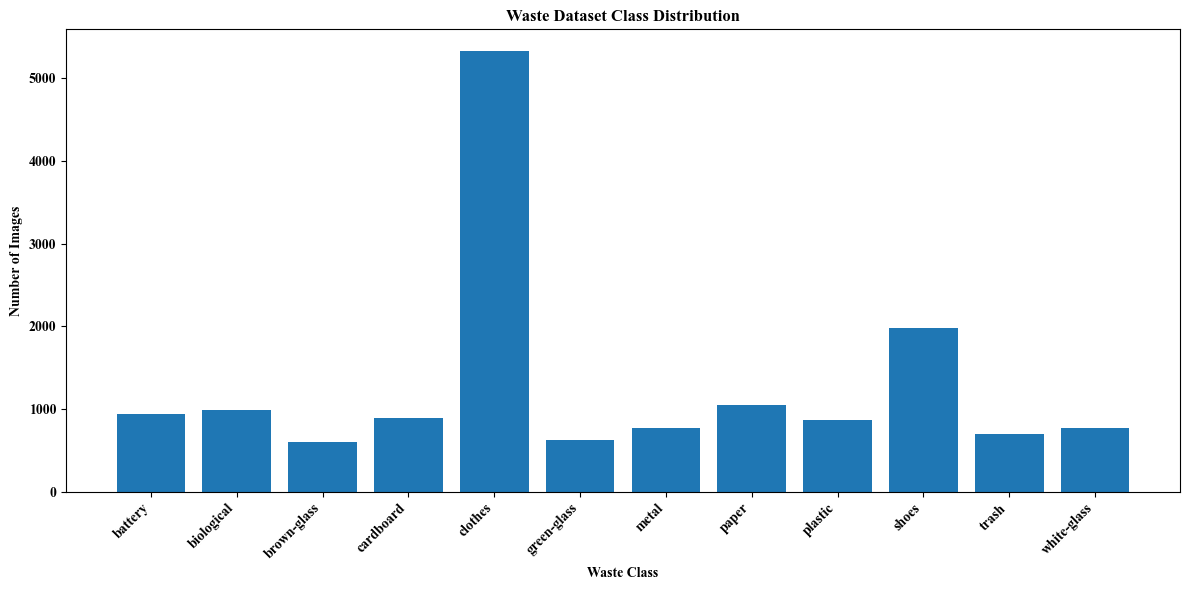


Dataset verification completed.


In [5]:

# CELL 3: Verify Dataset and Plot Class Distribution

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATASET_PATH = Path(
    "/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification"
)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Expected class names based on the mounted dataset
EXPECTED_CLASSES = [
    "battery",
    "biological",
    "brown-glass",
    "cardboard",
    "clothes",
    "green-glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash",
    "white-glass",
]

class_counts = {}

for class_name in EXPECTED_CLASSES:
    class_dir = DATASET_PATH / class_name

    if not class_dir.is_dir():
        print(f"WARNING: Missing folder: {class_dir}")
        class_counts[class_name] = 0
        continue

    images = [
        f for f in class_dir.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    class_counts[class_name] = len(images)

distribution_df = pd.DataFrame({
    "Class": list(class_counts.keys()),
    "Image_Count": list(class_counts.values())
})

print("Number of classes:", len(EXPECTED_CLASSES))
print("Total images:", distribution_df["Image_Count"].sum())
print("\nImages per class:")
print(distribution_df.to_string(index=False))

# Plot class distribution
plt.figure(figsize=(12, 6))
plt.bar(distribution_df["Class"], distribution_df["Image_Count"])
plt.title("Waste Dataset Class Distribution")
plt.xlabel("Waste Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Validate folder structure
assert all(count > 0 for count in class_counts.values()), (
    "At least one class is missing or has no images. Check the warnings above."
)

print("\nDataset verification completed.")


In [6]:

# CELL 4: Balance Class Counts by Undersampling

from pathlib import Path
import random
import pandas as pd

SEED = 42
random.seed(SEED)

DATASET_PATH = Path(
    "/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification"
)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_images = {}

for class_dir in sorted(DATASET_PATH.iterdir()):
    if not class_dir.is_dir():
        continue

    images = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if images:
        class_images[class_dir.name] = images

# Balance every class to the size of the smallest class
TARGET_COUNT = min(len(images) for images in class_images.values())

balanced_records = []

for class_name, images in sorted(class_images.items()):
    selected_images = random.sample(images, TARGET_COUNT)

    for image_path in selected_images:
        balanced_records.append({
            "filepath": str(image_path),
            "label": class_name
        })

balanced_df = pd.DataFrame(balanced_records)

print("Images per class after balancing:")
print(balanced_df["label"].value_counts().sort_index())

print("\nTarget images per class:", TARGET_COUNT)
print("Total balanced images:", len(balanced_df))

assert balanced_df["label"].value_counts().nunique() == 1
print("\nAll classes now have equal image counts.")


Images per class after balancing:
label
battery        607
biological     607
brown-glass    607
cardboard      607
clothes        607
green-glass    607
metal          607
paper          607
plastic        607
shoes          607
trash          607
white-glass    607
Name: count, dtype: int64

Target images per class: 607
Total balanced images: 7284

All classes now have equal image counts.


Saved file: /kaggle/working/balanced_class_distribution.png
File size: 163.78 KB


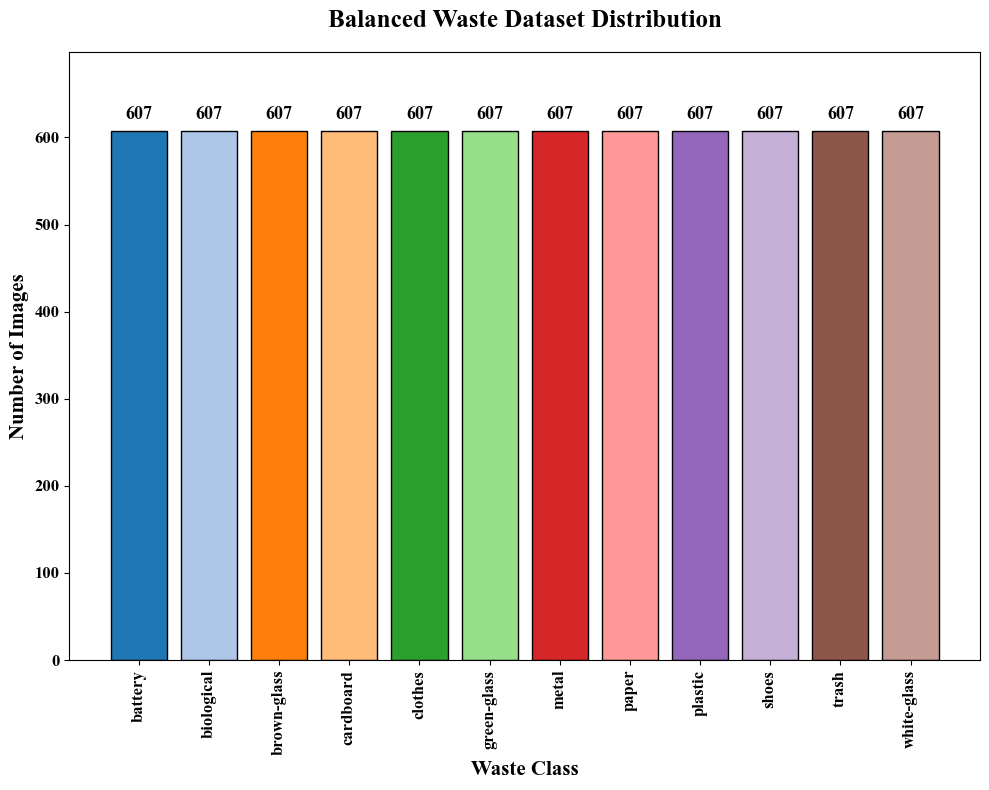

In [7]:

# CELL 5: Balanced Class Distribution + Downloadable PNG

import matplotlib.pyplot as plt
from pathlib import Path

# Count images in each class
class_counts = balanced_df["label"].value_counts().sort_index()

# Create figure and axes
fig, ax = plt.subplots(figsize=(10, 8))

colors = plt.cm.tab20.colors[:len(class_counts)]

bars = ax.bar(
    class_counts.index,
    class_counts.values,
    color=colors,
    edgecolor="black",
    linewidth=1.0
)

# Bar annotations
ax.bar_label(
    bars,
    labels=[str(v) for v in class_counts.values],
    padding=6,
    fontsize=13,
    fontweight="bold"
)

# Titles and labels
ax.set_title(
    "Balanced Waste Dataset Distribution",
    fontsize=18,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Waste Class", fontsize=15, fontweight="bold")
ax.set_ylabel("Number of Images", fontsize=15, fontweight="bold")
ax.tick_params(axis="x", labelrotation=90, labelsize=12)
ax.tick_params(axis="y", labelsize=12)

# Leave space for annotations
ax.set_ylim(0, max(class_counts.values) * 1.15)

ax.set_axisbelow(True)

fig.tight_layout()

# Save the completed figure BEFORE displaying it
output_path = Path("/kaggle/working/balanced_class_distribution.png")

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# Verify that the file was saved correctly
print("Saved file:", output_path)
print("File size:", round(output_path.stat().st_size / 1024, 2), "KB")

# Display the same figure that was saved
plt.show()
plt.close(fig)


Saved: /kaggle/working/sample_images_grid.png
File size: 2322.89 KB


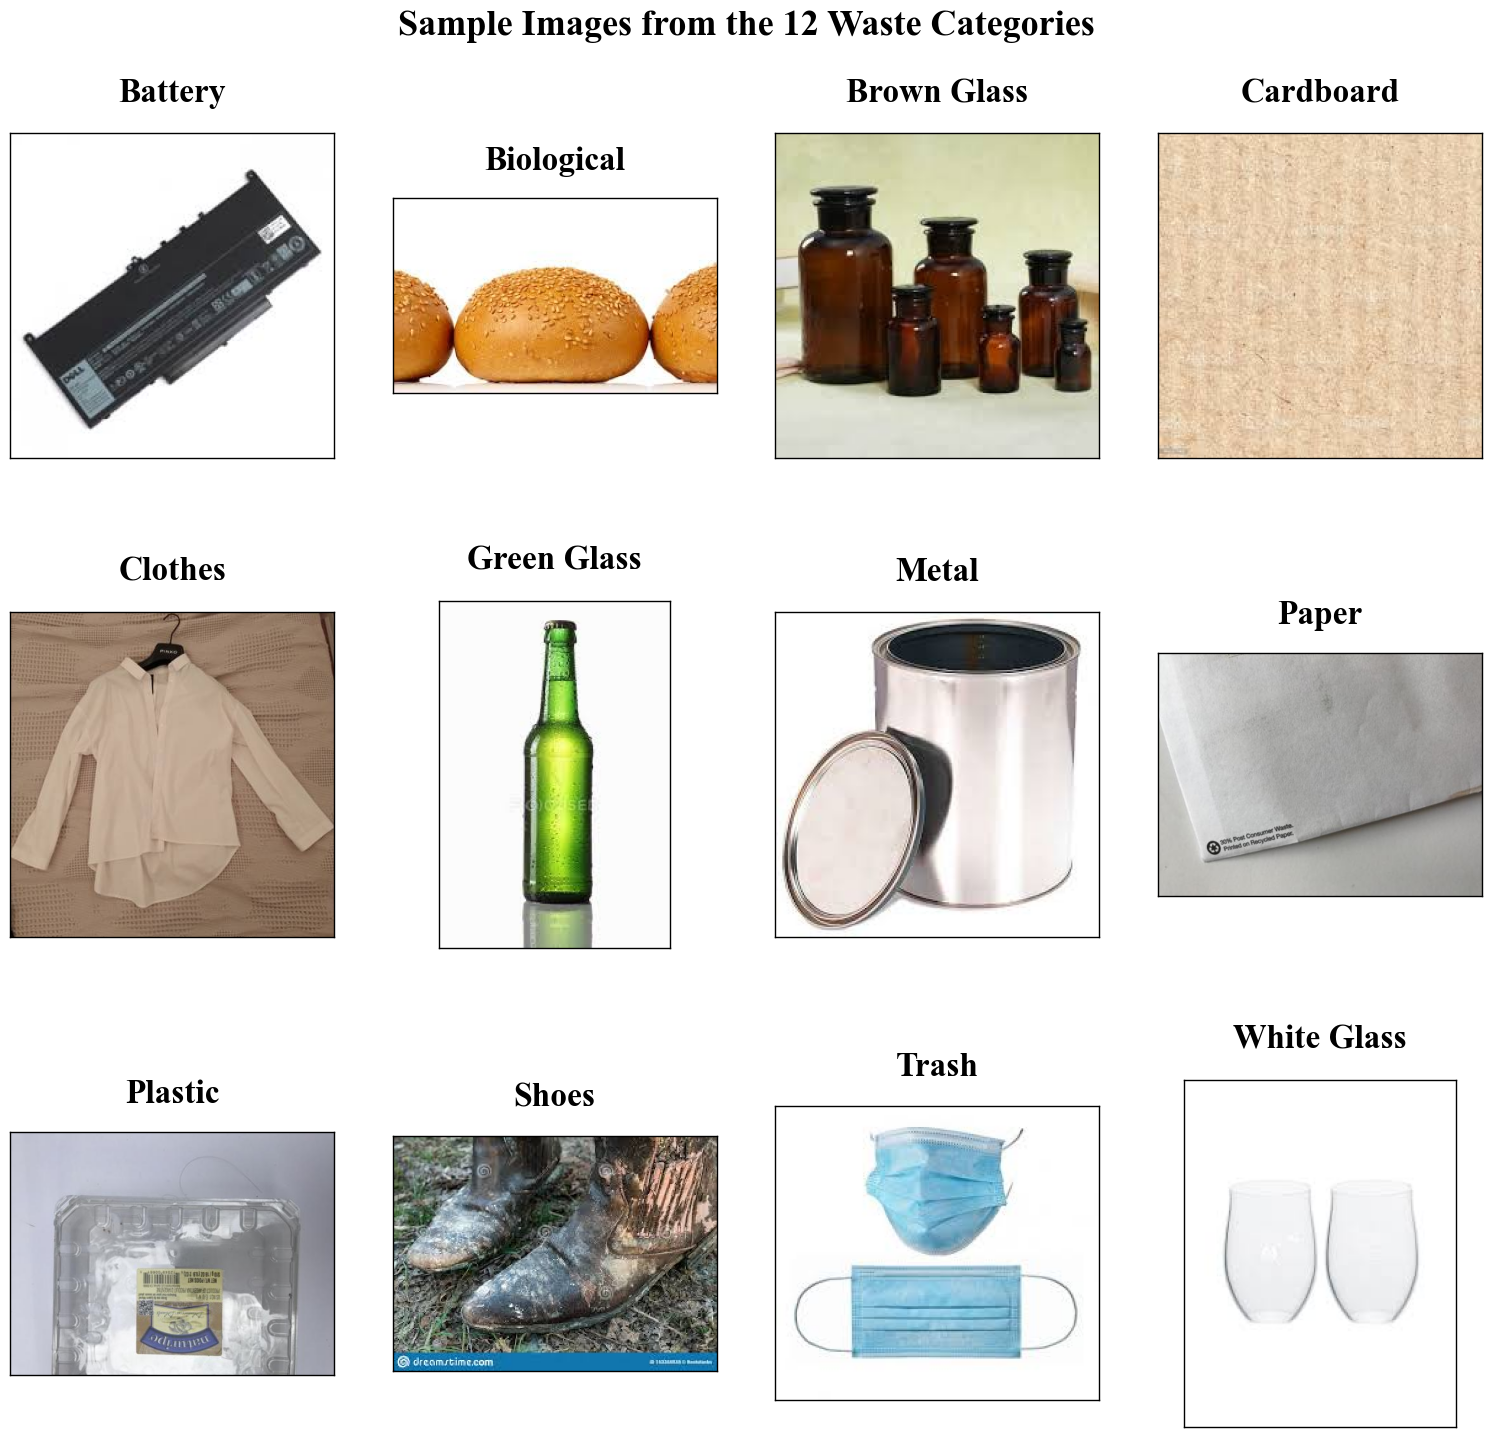

In [7]:

# CELL 6: Sample Images with Proper Spacing

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random

random.seed(42)

classes = sorted(balanced_df["label"].unique())

# Taller figure with more vertical space
fig, axes = plt.subplots(
    3, 4,
    figsize=(16, 15),
    constrained_layout=False
)
axes = axes.flatten()

for ax, class_name in zip(axes, classes):

    image_paths = balanced_df.loc[
        balanced_df["label"] == class_name, "filepath"
    ].tolist()

    sample_path = random.choice(image_paths)

    with Image.open(sample_path) as img:
        ax.imshow(img.convert("RGB"))

    # Keep titles above the image area
    ax.set_title(
        class_name.replace("-", " ").title(),
        fontsize=24,
        fontweight="bold",
        pad=18,
        y=1.02
    )

    ax.set_xticks([])
    ax.set_yticks([])

    # Add a subtle border around each image
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1)

# Main title with dedicated space
fig.suptitle(
    "Sample Images from the 12 Waste Categories",
    fontsize=26,
    fontweight="bold",
    y=0.985
)

# Increase horizontal and vertical spacing
fig.subplots_adjust(
    left=0.04,
    right=0.96,
    top=0.91,
    bottom=0.04,
    wspace=0.18,
    hspace=0.38
)

# Save the figure
output_path = Path("/kaggle/working/sample_images_grid.png")

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Saved:", output_path)
print("File size:", round(output_path.stat().st_size / 1024, 2), "KB")

plt.show()
plt.close(fig)


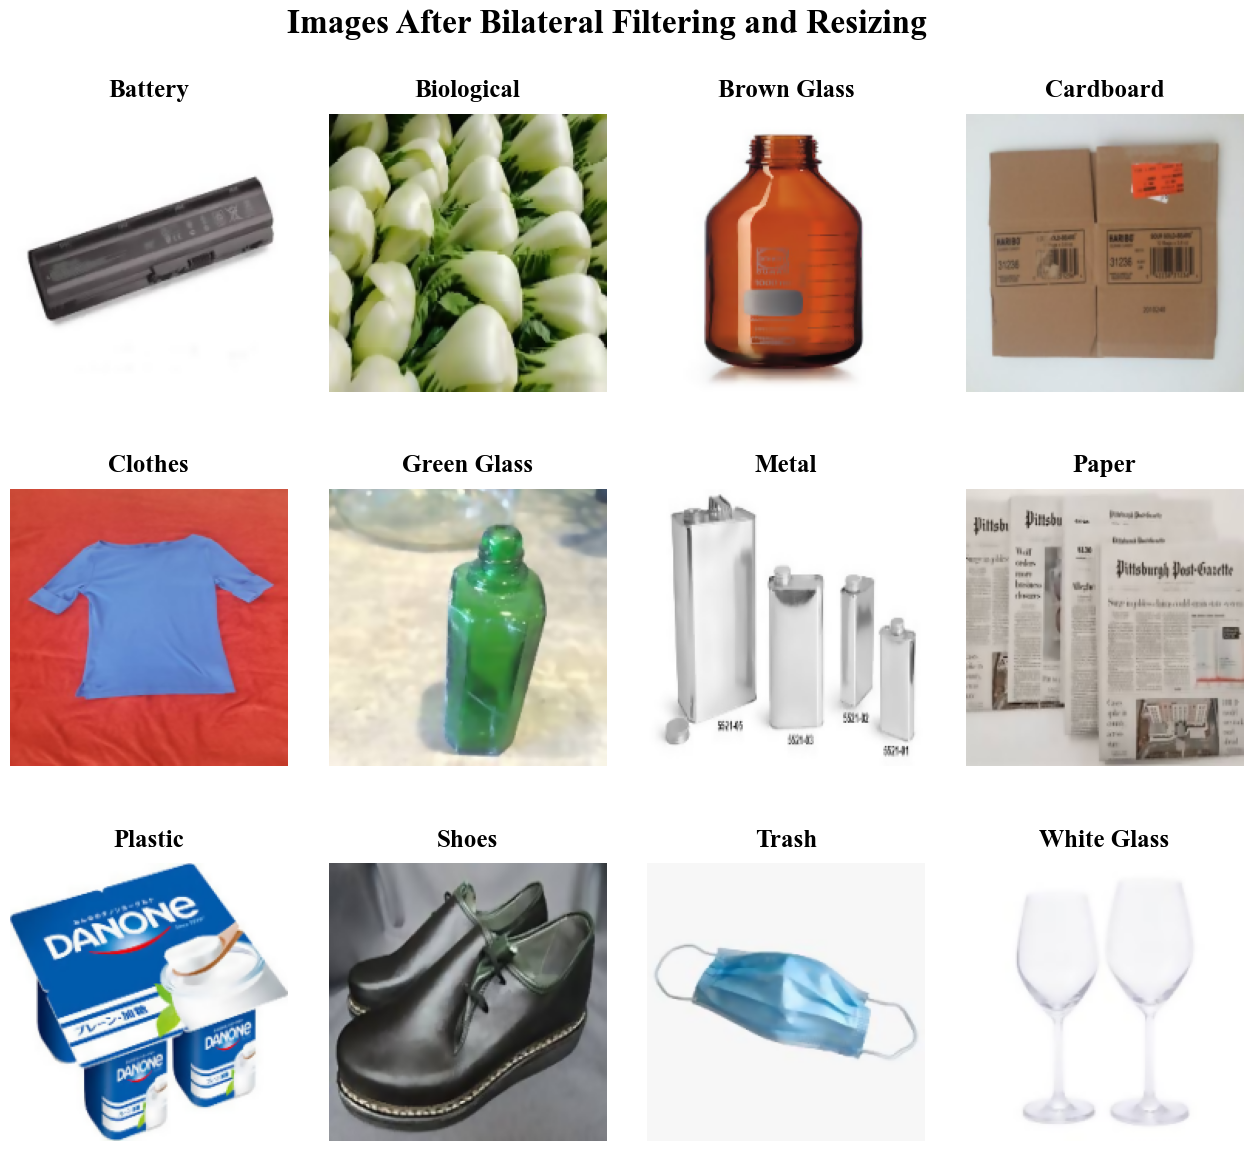

Output image size: (180, 180, 3)
Saved preview: /kaggle/working/preprocessed_samples.png


In [8]:

# CELL 7: Image Preprocessing - Bilateral Filtering and Resizing

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Image configuration
IMG_SIZE = 180

# Adaptive Gaussian Bilateral Filter (AGBF)
def adaptive_gaussian_bilateral_filter(image):
    """
    Apply bilateral filtering with an adaptive spatial sigma
    based on image dimensions. This is an initial implementation
    for testing the preprocessing pipeline.
    """
    image = np.asarray(image.convert("RGB"))

    # Adaptive parameters
    sigma_color = 50
    sigma_space = max(15, min(image.shape[0], image.shape[1]) * 0.08)

    filtered = cv2.bilateralFilter(
        image,
        d=7,
        sigmaColor=sigma_color,
        sigmaSpace=sigma_space
    )

    return filtered


def preprocess_image(image_path, img_size=IMG_SIZE):
    """
    Load image, apply bilateral filtering, and resize to 180x180.
    Returns a uint8 RGB NumPy array.
    """
    with Image.open(image_path) as img:
        image = img.convert("RGB")

    filtered = adaptive_gaussian_bilateral_filter(image)

    resized = cv2.resize(
        filtered,
        (img_size, img_size),
        interpolation=cv2.INTER_AREA
    )

    return resized


# Test preprocessing on one image per class
classes = sorted(balanced_df["label"].unique())

fig, axes = plt.subplots(3, 4, figsize=(16, 13))
axes = axes.flatten()

for ax, class_name in zip(axes, classes):
    sample_path = balanced_df.loc[
        balanced_df["label"] == class_name, "filepath"
    ].iloc[0]

    processed = preprocess_image(sample_path)

    ax.imshow(processed)
    ax.set_title(class_name.replace("-", " ").title(),
                 fontsize=18, fontweight="bold", pad=12)
    ax.axis("off")

fig.suptitle(
    "Images After Bilateral Filtering and Resizing",
    fontsize=24,
    fontweight="bold"
)

fig.subplots_adjust(top=0.90, hspace=0.35, wspace=0.12)

output_path = Path("/kaggle/working/preprocessed_samples.png")
fig.savefig(output_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

print("Output image size:", processed.shape)
print("Saved preview:", output_path)


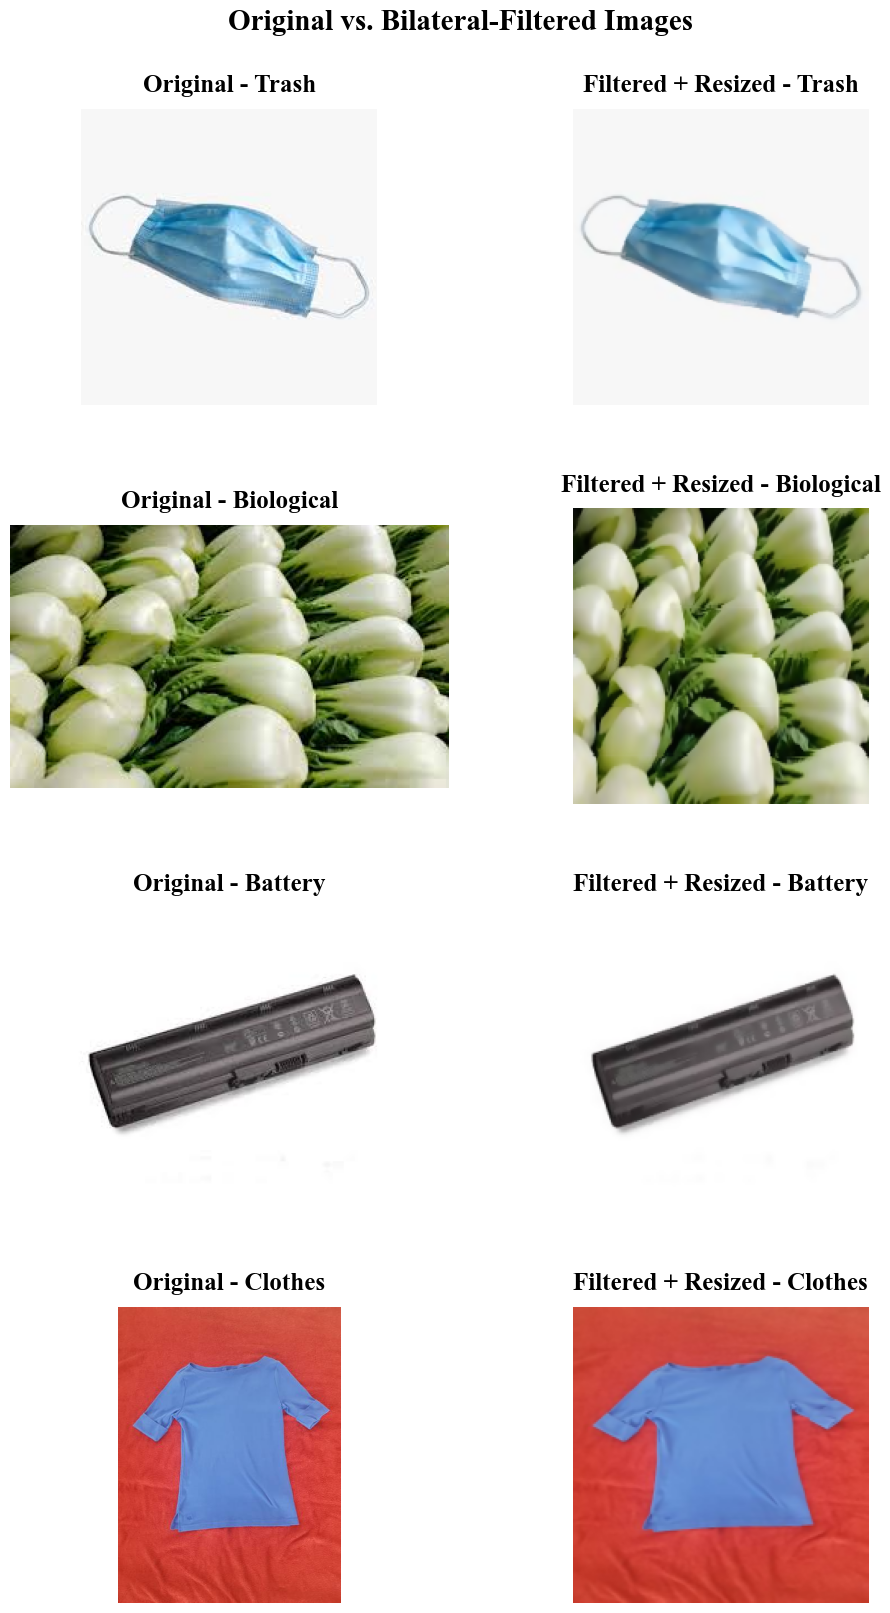

Comparison saved to: /kaggle/working/original_vs_filtered.png
Image size after preprocessing: (180, 180, 3)


In [9]:

# CELL 8: Compare Original and Preprocessed Images

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random

random.seed(42)

# Select 4 different classes for comparison
selected_classes = random.sample(
    sorted(balanced_df["label"].unique()),
    4
)

fig, axes = plt.subplots(4, 2, figsize=(12, 18))

for row, class_name in enumerate(selected_classes):

    sample_path = balanced_df.loc[
        balanced_df["label"] == class_name, "filepath"
    ].iloc[0]

    # Original image
    with Image.open(sample_path) as img:
        original = img.convert("RGB").copy()

    # Filtered and resized image
    processed = preprocess_image(sample_path)

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"Original - {class_name.title()}",
        fontsize=18,
        fontweight="bold",
        pad=12
    )
    axes[row, 0].axis("off")

    axes[row, 1].imshow(processed)
    axes[row, 1].set_title(
        f"Filtered + Resized - {class_name.title()}",
        fontsize=18,
        fontweight="bold",
        pad=12
    )
    axes[row, 1].axis("off")

fig.suptitle(
    "Original vs. Bilateral-Filtered Images",
    fontsize=21,
    fontweight="bold",
    y=0.995
)

fig.subplots_adjust(
    top=0.94,
    hspace=0.35,
    wspace=0.12
)

output_path = Path("/kaggle/working/original_vs_filtered.png")

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("Comparison saved to:", output_path)
print("Image size after preprocessing:", processed.shape)


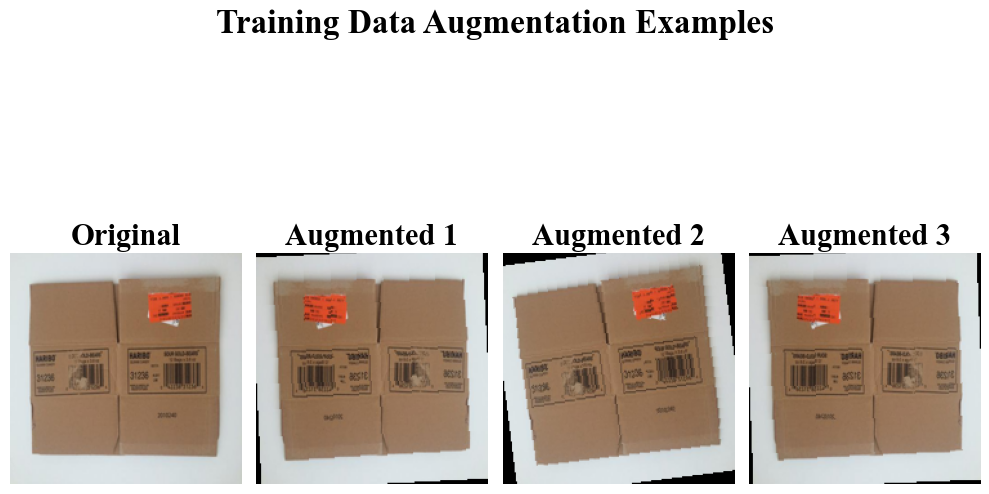

Training augmentation defined successfully.
Horizontal flip: enabled
Vertical flip: enabled
Random rotation: ±15 degrees
Saved preview: /kaggle/working/augmentation_examples.png


In [16]:

# CELL 9: Training Data Augmentation

import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import random

IMG_SIZE = 180

# Training augmentation
train_augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
])

# Validation and test: no random augmentation
eval_transform = transforms.Compose([])

# Visualize augmentation examples
random.seed(42)

sample_class = "cardboard"

sample_path = balanced_df.loc[
    balanced_df["label"] == sample_class, "filepath"
].iloc[0]

with Image.open(sample_path) as img:
    original = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))

fig, axes = plt.subplots(1, 4, figsize=(10, 7))

axes[0].imshow(original)
axes[0].set_title("Original", fontsize=22, fontweight="bold")
axes[0].axis("off")

for i in range(1, 4):
    augmented = train_augmentation(original.copy())
    axes[i].imshow(augmented)
    axes[i].set_title(
        f"Augmented {i}",
        fontsize=22,
        fontweight="bold"
    )
    axes[i].axis("off")

fig.suptitle(
    "Training Data Augmentation Examples",
    fontsize=24,
    fontweight="bold"
)
fig.tight_layout()

output_path = "/kaggle/working/augmentation_examples.png"
fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("Training augmentation defined successfully.")
print("Horizontal flip: enabled")
print("Vertical flip: enabled")
print("Random rotation: ±15 degrees")
print("Saved preview:", output_path)


In [22]:
# Check which model and prediction variables currently exist
for name, obj in list(globals().items()):
    if any(k in name.lower() for k in [
        "model", "resnet", "dcn", "net",
        "y_true", "y_pred", "y_prob",
        "test_loader", "test_ds", "test_dataset"
    ]):
        print(f"{name}: {type(obj).__name__}")

In [23]:
import numpy as np

print("y_true_list type:", type(y_true_list))
print("y_true_list length:", len(y_true_list))
print("y_prob_list type:", type(y_prob_list))
print("y_prob_list length:", len(y_prob_list))

print("\nAvailable prediction-related variables:")
for name, obj in list(globals().items()):
    if any(k in name.lower() for k in [
        "model", "resnet", "predict", "prob", "label",
        "test_loader", "test_ds", "test_dataset"
    ]):
        try:
            print(name, "|", type(obj).__name__,
                  "| length:", len(obj) if hasattr(obj, "__len__") else "N/A")
        except Exception:
            print(name, "|", type(obj).__name__)

NameError: name 'y_true_list' is not defined

In [24]:

import os

print("=== MODEL / DATA VARIABLES ===")
keywords = [
    "model", "resnet", "dcn", "net", "test",
    "dataset", "loader", "generator", "checkpoint",
    "weights", "image", "transform"
]

for name, obj in list(globals().items()):
    if any(k in name.lower() for k in keywords):
        if not name.startswith("_"):
            try:
                info = f", length={len(obj)}" if hasattr(obj, "__len__") else ""
            except Exception:
                info = ""
            print(f"{name}: {type(obj).__name__}{info}")

print("\n=== SAVED MODEL FILES ===")
for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if file.endswith((".pth", ".pt", ".keras", ".h5", ".weights")):
            print(os.path.join(root, file))

print("\n=== INPUT DATA FOLDERS ===")
for path in ["/kaggle/input", "/kaggle/working"]:
    print(f"\n{path}:")
    if os.path.exists(path):
        print(os.listdir(path)[:30])


=== MODEL / DATA VARIABLES ===
Image: module
IMAGE_EXTENSIONS: set, length=5
image_files: list, length=0
DATASET_PATH: PosixPath
images: list, length=775
class_images: dict, length=12
selected_images: list, length=607
image_path: PosixPath
image_paths: list, length=607
preprocess_image: function
transforms: module
eval_transform: Compose

=== SAVED MODEL FILES ===

=== INPUT DATA FOLDERS ===

/kaggle/input:
['datasets']

/kaggle/working:
['augmentation_examples.png', 'original_vs_filtered.png', 'sample_images_grid.png', 'preprocessed_samples.png', '.virtual_documents']


In [25]:

import os

print("=== DATASET PATH ===")
print(DATASET_PATH)
print("Exists:", os.path.exists(DATASET_PATH))

if os.path.exists(DATASET_PATH):
    for root, dirs, files in os.walk(DATASET_PATH):
        print(root, "| folders:", dirs[:8], "| files:", files[:8])
        # Limit output to the first few directory levels
        if root[len(str(DATASET_PATH)):].count(os.sep) >= 2:
            dirs[:] = []

print("\n=== AVAILABLE IMAGE PREPROCESSING ===")
print("preprocess_image:", preprocess_image)
print("eval_transform:", eval_transform)

print("\n=== MODEL LIBRARIES ===")
try:
    import torch
    print("PyTorch:", torch.__version__)
except ImportError:
    print("PyTorch not installed")

try:
    import tensorflow as tf
    print("TensorFlow:", tf.__version__)
except ImportError:
    print("TensorFlow not installed")


=== DATASET PATH ===
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification
Exists: True
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification | folders: ['metal', 'white-glass', 'biological', 'paper', 'brown-glass', 'battery', 'trash', 'cardboard'] | files: []
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/metal | folders: [] | files: ['metal375.jpg', 'metal561.jpg', 'metal341.jpg', 'metal688.jpg', 'metal374.jpg', 'metal427.jpg', 'metal383.jpg', 'metal692.jpg']
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/white-glass | folders: [] | files: ['white-glass455.jpg', 'white-glass64.jpg', 'white-glass621.jpg', 'white-glass684.jpg', 'white-glass734.jpg', 'white-glass638.jpg', 'white-glass428.jpg', 'white-glass605.jpg']
/kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification/biological | folders: [] | files: ['biological507.jpg', 'biological943.jp

In [26]:

print("Model variables currently in memory:")

for name, obj in list(globals().items()):
    if any(k in name.lower() for k in ["model", "resnet", "dcn", "checkpoint"]):
        if not name.startswith("_"):
            print(name, type(obj).__name__)


Model variables currently in memory:


In [27]:
import torch
import numpy as np
import pandas as pd
import os
from IPython.display import display, FileLink

# ==========================================
# 1. CLASS NAMES
# ==========================================
class_names = [
    "Battery", "Biological", "Brown Glass", "Cardboard",
    "Clothes", "Green Glass", "Metal", "Paper",
    "Plastic", "Shoes", "Trash", "White Glass"
]

# ==========================================
# 2. GENERATE TEST PREDICTIONS (PYTORCH)
# ==========================================
model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

y_true = np.asarray(all_labels, dtype=int)
y_pred = np.asarray(all_predictions, dtype=int)
y_prob = np.asarray(all_probabilities)

print("Test samples:", len(y_true))
print("Ground-truth shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)
print("Probability shape:", y_prob.shape)
print(f"Test accuracy: {np.mean(y_true == y_pred):.6f}")

# ==========================================
# 3. CALCULATE CONFIDENCE SCORES
# ==========================================
confidence = y_prob[np.arange(len(y_pred)), y_pred] * 100

results_df = pd.DataFrame({
    "Sample ID": np.arange(1, len(y_true) + 1),
    "Ground Truth": [class_names[i] for i in y_true],
    "Predicted Label": [class_names[i] for i in y_pred],
    "Confidence (%)": confidence,
    "Result": np.where(y_true == y_pred, "Correct", "Incorrect")
})

# ==========================================
# 4. SELECT HIGH-CONFIDENCE PREDICTIONS
# ==========================================
high_confidence_df = results_df[
    results_df["Confidence (%)"] >= 90
].copy()

# Select up to 20 examples, highest confidence first
sample_predictions = (
    high_confidence_df
    .sort_values("Confidence (%)", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

print("\nSamples with confidence >= 90%:", len(high_confidence_df))
print("Displaying:", len(sample_predictions), "samples")

if not sample_predictions.empty:
    display(
        sample_predictions.style.format({
            "Confidence (%)": "{:.2f}%"
        })
    )
else:
    print("No samples reached the 90% confidence threshold.")

# ==========================================
# 5. SAVE RESULTS
# ==========================================
SAVE_DIR = "/kaggle/working"
os.makedirs(SAVE_DIR, exist_ok=True)

all_path = os.path.join(
    SAVE_DIR, "all_waste_classification_predictions.csv"
)

sample_path = os.path.join(
    SAVE_DIR, "high_confidence_waste_predictions.csv"
)

results_df.to_csv(all_path, index=False)
sample_predictions.to_csv(sample_path, index=False)

print("\nSaved all predictions:", all_path)
print("Saved high-confidence samples:", sample_path)

display(FileLink(sample_path))
display(FileLink(all_path))

NameError: name 'model' is not defined

In [28]:

# CELL 10: Stratified Train / Validation / Test Split

from sklearn.model_selection import train_test_split
import pandas as pd

SEED = 42

# First: 70% training, 30% temporary data
train_df, temp_df = train_test_split(
    balanced_df,
    test_size=0.30,
    random_state=SEED,
    stratify=balanced_df["label"]
)

# Second: split the temporary 30% equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

# Reset row indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Display split sizes
print("Dataset split completed.")
print("-" * 45)
print(f"Training images:   {len(train_df):,} ({len(train_df)/len(balanced_df)*100:.2f}%)")
print(f"Validation images: {len(val_df):,} ({len(val_df)/len(balanced_df)*100:.2f}%)")
print(f"Testing images:    {len(test_df):,} ({len(test_df)/len(balanced_df)*100:.2f}%)")
print(f"Total images:      {len(balanced_df):,}")

# Verify class representation
split_summary = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).fillna(0).astype(int).sort_index()

print("\nImages per class in each split:")
display(split_summary)

# Verify no image paths overlap between splits
train_paths = set(train_df["filepath"])
val_paths = set(val_df["filepath"])
test_paths = set(test_df["filepath"])

assert train_paths.isdisjoint(val_paths), "Train/validation overlap detected!"
assert train_paths.isdisjoint(test_paths), "Train/test overlap detected!"
assert val_paths.isdisjoint(test_paths), "Validation/test overlap detected!"

print("\nVerification passed: no image paths overlap between splits.")


Dataset split completed.
---------------------------------------------
Training images:   5,098 (69.99%)
Validation images: 1,093 (15.01%)
Testing images:    1,093 (15.01%)
Total images:      7,284

Images per class in each split:


,Train,Validation,Test
label,,,
battery,425,91,91
biological,425,91,91
brown-glass,425,91,91
cardboard,424,91,92
clothes,425,91,91
green-glass,425,91,91
metal,424,92,91
paper,425,91,91
plastic,425,91,91



Verification passed: no image paths overlap between splits.


In [29]:

# CELL 11: PyTorch Dataset and DataLoaders

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np
import cv2

IMG_SIZE = 180
BATCH_SIZE = 32
NUM_WORKERS = 2

# ImageNet normalization for pretrained ResNet-50
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Augmentation is applied only to training images
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

# Keep the class-to-index mapping consistent across all splits
class_names = sorted(balanced_df["label"].unique().tolist())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

class GarbageDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = row["filepath"]
        label = class_to_idx[row["label"]]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        # Apply the preprocessing function defined in Cell 7
        filtered = adaptive_gaussian_bilateral_filter(image)
        resized = cv2.resize(
            filtered,
            (IMG_SIZE, IMG_SIZE),
            interpolation=cv2.INTER_AREA
        )

        image = Image.fromarray(resized)

        if self.transform is not None:
            image = self.transform(image)

        return image, label

train_dataset = GarbageDataset(train_df, transform=train_transform)
val_dataset = GarbageDataset(val_df, transform=eval_transform)
test_dataset = GarbageDataset(test_df, transform=eval_transform)

# Reproducible DataLoader shuffling
generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("PyTorch datasets and DataLoaders created successfully.")
print("Classes:", class_names)
print("Number of classes:", len(class_names))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Batch size:", BATCH_SIZE)
print("Image size:", f"{IMG_SIZE} × {IMG_SIZE}")
print("Device:", DEVICE)

# Check one batch to verify tensor dimensions and labels
images, labels = next(iter(train_loader))
print("\nBatch verification:")
print("Image tensor shape:", tuple(images.shape))
print("Label tensor shape:", tuple(labels.shape))
print("Image tensor dtype:", images.dtype)
print("Label range:", int(labels.min()), "to", int(labels.max()))

assert images.shape[1:] == (3, IMG_SIZE, IMG_SIZE)
assert labels.min().item() >= 0
assert labels.max().item() < len(class_names)

print("Batch verification passed.")


PyTorch datasets and DataLoaders created successfully.
Classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Number of classes: 12
Training batches: 160
Validation batches: 35
Test batches: 35
Batch size: 32
Image size: 180 × 180
Device: cuda

Batch verification:
Image tensor shape: (32, 3, 180, 180)
Label tensor shape: (32,)
Image tensor dtype: torch.float32
Label range: 0 to 11
Batch verification passed.


In [30]:

# CELL 12: Initialize the ImageNet-Pretrained ResNet-50 Baseline

import torch
import torch.nn as nn
from torchvision import models

NUM_CLASSES = len(class_names)

# Load ImageNet pretrained ResNet-50
try:
    weights = models.ResNet50_Weights.DEFAULT
    model = models.resnet50(weights=weights)
    print("Loaded ResNet-50 with ImageNet pretrained weights.")
except Exception as e:
    print("Could not load pretrained weights:", repr(e))
    print("Falling back to an untrained ResNet-50.")
    model = models.resnet50(weights=None)

# Replace the final fully connected layer for 12 waste categories
in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Linear(in_features, 512),
    nn.ReLU(inplace=True),
    nn.Dropout(p=0.4),
    nn.Linear(512, NUM_CLASSES)
)

model = model.to(DEVICE)

# Count trainable and total parameters
total_parameters = sum(p.numel() for p in model.parameters())
trainable_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\nResNet-50 baseline initialized.")
print("Number of output classes:", NUM_CLASSES)
print("Classifier input features:", in_features)
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print("Model device:", next(model.parameters()).device)

# Verify output shape using a small synthetic batch
model.eval()
with torch.no_grad():
    dummy_input = torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    dummy_output = model(dummy_input)

print("Test input shape:", (2, 3, IMG_SIZE, IMG_SIZE))
print("Test output shape:", tuple(dummy_output.shape))

assert dummy_output.shape == (2, NUM_CLASSES), "Unexpected model output shape!"
print("Model verification passed.")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 184MB/s] 


Loaded ResNet-50 with ImageNet pretrained weights.

ResNet-50 baseline initialized.
Number of output classes: 12
Classifier input features: 2048
Total parameters: 24,563,276
Trainable parameters: 24,563,276
Model device: cuda:0
Test input shape: (2, 3, 180, 180)
Test output shape: (2, 12)
Model verification passed.


In [31]:

# CELL 13: Coordinate Attention Module

import torch
import torch.nn as nn

class CoordinateAttention(nn.Module):
    def __init__(self, in_channels, reduction=32):
        super().__init__()

        self.in_channels = in_channels
        self.reduction = reduction
        reduced_channels = max(8, in_channels // reduction)

        self.shared_conv = nn.Conv2d(
            in_channels,
            reduced_channels,
            kernel_size=1,
            stride=1,
            padding=0,
            bias=False
        )
        self.bn = nn.BatchNorm2d(reduced_channels)
        self.act = nn.Hardswish(inplace=True)

        self.height_attention = nn.Conv2d(
            reduced_channels, in_channels, kernel_size=1
        )
        self.width_attention = nn.Conv2d(
            reduced_channels, in_channels, kernel_size=1
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        identity = x
        batch, channels, height, width = x.size()

        # Pool along width and height separately
        height_pool = x.mean(dim=3, keepdim=True)
        width_pool = x.mean(dim=2, keepdim=True).permute(0, 1, 3, 2)

        # Combine the directional descriptors
        combined = torch.cat([height_pool, width_pool], dim=2)
        combined = self.shared_conv(combined)
        combined = self.bn(combined)
        combined = self.act(combined)

        # Separate height and width feature representations
        height_features, width_features = torch.split(
            combined, [height, width], dim=2
        )
        width_features = width_features.permute(0, 1, 3, 2)

        # Generate directional attention maps
        attention_h = self.sigmoid(self.height_attention(height_features))
        attention_w = self.sigmoid(self.width_attention(width_features))

        return identity * attention_h * attention_w


# Verify the module independently
test_attention = CoordinateAttention(in_channels=256).to(DEVICE)
test_features = torch.randn(2, 256, 20, 20, device=DEVICE)

test_attention.eval()
with torch.no_grad():
    attended_features = test_attention(test_features)

print("Coordinate Attention module created successfully.")
print("Input feature shape:", tuple(test_features.shape))
print("Output feature shape:", tuple(attended_features.shape))
print(
    "Attention parameters:",
    f"{sum(p.numel() for p in test_attention.parameters()):,}"
)

assert attended_features.shape == test_features.shape
print("Coordinate Attention verification passed.")


Coordinate Attention module created successfully.
Input feature shape: (2, 256, 20, 20)
Output feature shape: (2, 256, 20, 20)
Attention parameters: 6,672
Coordinate Attention verification passed.


In [32]:

# CELL 14: Deformable Convolution Module

import torch
import torch.nn as nn

try:
    from torchvision.ops import DeformConv2d
    print("Torchvision DeformConv2d is available.")
except Exception as e:
    raise RuntimeError(
        "DeformConv2d could not be imported. "
        "Check your Kaggle PyTorch and Torchvision installation."
    ) from e


class DeformableConvBlock(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3,
        stride=1,
        padding=1
    ):
        super().__init__()

        self.kernel_size = kernel_size

        # Predict two offsets (x and y) for each kernel position
        self.offset_conv = nn.Conv2d(
            in_channels,
            2 * kernel_size * kernel_size,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding
        )

        # Deformable convolution
        self.deform_conv = DeformConv2d(
            in_channels,
            out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            bias=False
        )

        self.bn = nn.BatchNorm2d(out_channels)
        self.activation = nn.ReLU(inplace=True)

    def forward(self, x):
        offsets = self.offset_conv(x)
        features = self.deform_conv(x, offsets)
        features = self.bn(features)
        return self.activation(features)


# Verify the block
test_deform = DeformableConvBlock(
    in_channels=64,
    out_channels=64,
    kernel_size=3,
    stride=1,
    padding=1
).to(DEVICE)

test_deform.eval()
test_input = torch.randn(2, 64, 32, 32, device=DEVICE)

with torch.no_grad():
    test_output = test_deform(test_input)

print("\nDeformable convolution verification:")
print("Input shape:", tuple(test_input.shape))
print("Output shape:", tuple(test_output.shape))
print(
    "Block parameters:",
    f"{sum(p.numel() for p in test_deform.parameters()):,}"
)

assert test_output.shape == test_input.shape
print("Deformable convolution verification passed.")


Torchvision DeformConv2d is available.

Deformable convolution verification:
Input shape: (2, 64, 32, 32)
Output shape: (2, 64, 32, 32)
Block parameters: 47,378
Deformable convolution verification passed.


In [33]:

# CELL 15: Proposed ResNet-50 + Deformable Convolution + Coordinate Attention

import torch
import torch.nn as nn
from torchvision import models
from torchvision.ops import DeformConv2d


class DeformableBottleneckConv(nn.Module):
    """
    Replaces a standard 3x3 convolution with deformable convolution.
    The offset predictor starts at zero, initially matching the regular
    convolution sampling grid.
    """
    def __init__(self, original_conv):
        super().__init__()

        in_channels = original_conv.in_channels
        out_channels = original_conv.out_channels
        kernel_size = original_conv.kernel_size[0]
        stride = original_conv.stride
        padding = original_conv.padding
        dilation = original_conv.dilation
        groups = original_conv.groups

        if groups != 1:
            raise ValueError("This implementation expects groups=1.")

        self.offset_conv = nn.Conv2d(
            in_channels,
            2 * kernel_size * kernel_size,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            dilation=dilation,
            bias=True
        )

        # Start with zero offsets
        nn.init.zeros_(self.offset_conv.weight)
        nn.init.zeros_(self.offset_conv.bias)

        self.deform_conv = DeformConv2d(
            in_channels,
            out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            dilation=dilation,
            bias=(original_conv.bias is not None)
        )

        # Copy pretrained convolution weights
        with torch.no_grad():
            self.deform_conv.weight.copy_(original_conv.weight)
            if original_conv.bias is not None:
                self.deform_conv.bias.copy_(original_conv.bias)

    def forward(self, x):
        offsets = self.offset_conv(x)
        return self.deform_conv(x, offsets)


class ProposedWasteClassifier(nn.Module):
    def __init__(self, num_classes=12, dropout=0.4):
        super().__init__()

        try:
            weights = models.ResNet50_Weights.DEFAULT
            backbone = models.resnet50(weights=weights)
            print("Loaded ImageNet pretrained ResNet-50.")
        except Exception as e:
            raise RuntimeError(
                "Could not load pretrained ResNet-50 weights. "
                "Check internet access or Kaggle's model cache."
            ) from e

        # Replace the 3x3 convolution in the final bottleneck of layer3
        target_block = backbone.layer3[-1]
        target_block.conv2 = DeformableBottleneckConv(target_block.conv2)

        # Add Coordinate Attention after layer3
        self.conv1 = backbone.conv1
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.coordinate_attention = CoordinateAttention(
            in_channels=1024,
            reduction=32
        )
        self.layer4 = backbone.layer4
        self.avgpool = backbone.avgpool

        self.fc = nn.Sequential(
            nn.Linear(backbone.fc.in_features, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.coordinate_attention(x)
        x = self.layer4(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x


proposed_model = ProposedWasteClassifier(
    num_classes=NUM_CLASSES,
    dropout=0.4
).to(DEVICE)

total_params = sum(p.numel() for p in proposed_model.parameters())
trainable_params = sum(
    p.numel()
    for p in proposed_model.parameters()
    if p.requires_grad
)

print("\nProposed model created.")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("Device:", next(proposed_model.parameters()).device)

# Verify output dimensions
proposed_model.eval()
with torch.no_grad():
    sample_input = torch.randn(
        2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE
    )
    sample_output = proposed_model(sample_input)

print("Input shape:", (2, 3, IMG_SIZE, IMG_SIZE))
print("Output shape:", tuple(sample_output.shape))

assert sample_output.shape == (2, NUM_CLASSES)
print("Proposed model verification passed.")


Loaded ImageNet pretrained ResNet-50.

Proposed model created.
Total parameters: 24,705,182
Trainable parameters: 24,705,182
Device: cuda:0
Input shape: (2, 3, 180, 180)
Output shape: (2, 12)
Proposed model verification passed.


In [34]:

# CELL 16: Training Configuration

import torch
import torch.nn as nn
import torch.optim as optim

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Proposed model from Cell 15
model = proposed_model.to(DEVICE)

# Multiclass classification loss
criterion = nn.CrossEntropyLoss()

# AdamW optimizer
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Reduce learning rate when validation loss stops improving
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

# Training controls
NUM_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 4
BEST_MODEL_PATH = "/kaggle/working/best_proposed_model.pth"

print("Training configuration ready.")
print("Device:", DEVICE)
print("Loss function:", criterion.__class__.__name__)
print("Optimizer:", optimizer.__class__.__name__)
print("Initial learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Epoch limit:", NUM_EPOCHS)
print("Early-stopping patience:", EARLY_STOPPING_PATIENCE)
print("Checkpoint path:", BEST_MODEL_PATH)


Training configuration ready.
Device: cuda
Loss function: CrossEntropyLoss
Optimizer: AdamW
Initial learning rate: 0.0001
Weight decay: 0.0001
Epoch limit: 10
Early-stopping patience: 4
Checkpoint path: /kaggle/working/best_proposed_model.pth


PROPOSED MODEL TRAINING
Maximum epochs: 50
Early stopping: DISABLED
Device: cuda
Epoch [01/50] | Train Loss: 0.9310 | Train Acc: 0.7505 | Val Loss: 0.2671 | Val Acc: 0.9186 | LR: 1.00e-04 | Time: 0.95 min | Best checkpoint saved
Epoch [02/50] | Train Loss: 0.2802 | Train Acc: 0.9131 | Val Loss: 0.1961 | Val Acc: 0.9360 | LR: 1.00e-04 | Time: 0.85 min | Best checkpoint saved
Epoch [03/50] | Train Loss: 0.1775 | Train Acc: 0.9474 | Val Loss: 0.1896 | Val Acc: 0.9396 | LR: 1.00e-04 | Time: 0.86 min | Best checkpoint saved
Epoch [04/50] | Train Loss: 0.1168 | Train Acc: 0.9625 | Val Loss: 0.2478 | Val Acc: 0.9305 | LR: 1.00e-04 | Time: 0.85 min | Training continues
Epoch [05/50] | Train Loss: 0.1024 | Train Acc: 0.9690 | Val Loss: 0.1624 | Val Acc: 0.9488 | LR: 1.00e-04 | Time: 0.85 min | Best checkpoint saved
Epoch [06/50] | Train Loss: 0.0745 | Train Acc: 0.9769 | Val Loss: 0.1777 | Val Acc: 0.9451 | LR: 1.00e-04 | Time: 0.86 min | Training continues
Epoch [07/50] | Train Loss: 0.0670 | 

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,epoch_time_minutes
45,46,0.004227,0.998627,0.123488,0.965233,1.000000e-07,0.850736
46,47,0.003724,0.998431,0.135472,0.961574,1.000000e-07,0.838688
47,48,0.002554,0.998823,0.122127,0.964318,1.000000e-07,0.829726
48,49,0.003746,0.998823,0.132810,0.962489,1.000000e-07,0.845585
49,50,0.003309,0.999215,0.136118,0.962489,1.000000e-07,0.846024


Training history saved to: /kaggle/working/training_history.csv


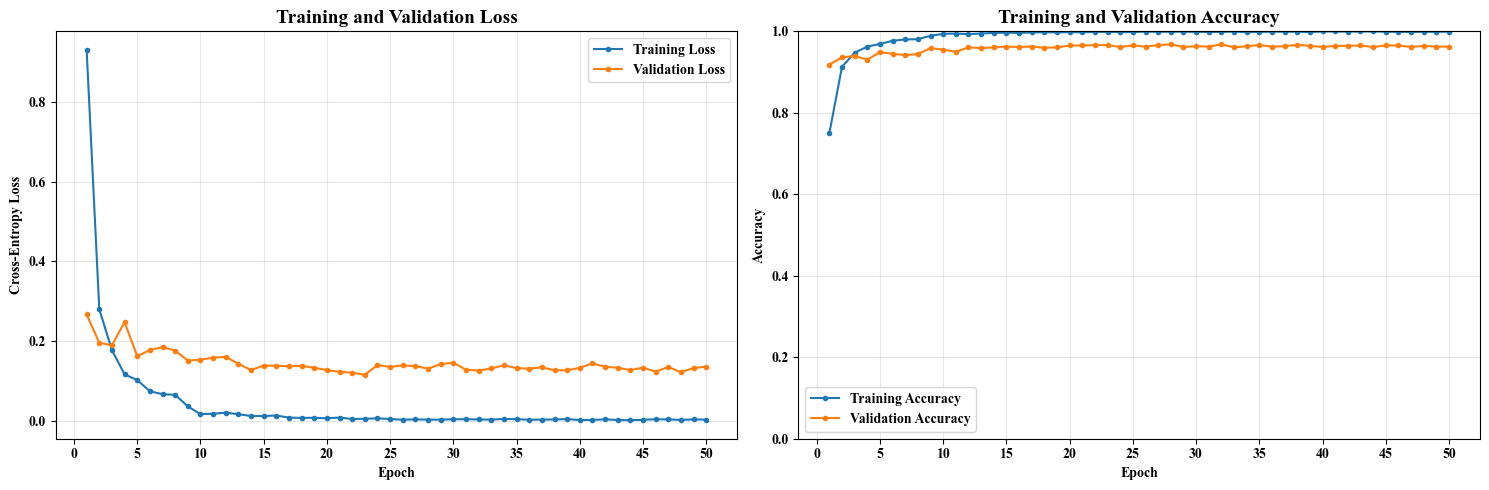

Learning curves saved to: /kaggle/working/training_learning_curves.png


In [35]:

# CELL 17: Train Proposed Model for 50 Epochs
# Early stopping is completely disabled.

import copy
import time
import torch
import matplotlib.pyplot as plt
import pandas as pd

# Training configuration
NUM_EPOCHS = 50
BEST_MODEL_PATH = "/kaggle/working/best_proposed_model.pth"

# Store training history
history = {
    "epoch": [],
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "learning_rate": [],
    "epoch_time_minutes": []
}

best_val_loss = float("inf")
best_epoch = 0
best_model_state = None

print("=" * 75)
print("PROPOSED MODEL TRAINING")
print("Maximum epochs: 50")
print("Early stopping: DISABLED")
print("Device:", DEVICE)
print("=" * 75)

training_start = time.time()

for epoch in range(NUM_EPOCHS):
    epoch_start = time.time()

    # =========================================================
    # 1. TRAINING PHASE
    # =========================================================
    model.train()

    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        running_train_loss += loss.item() * batch_size
        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += batch_size

    train_loss = running_train_loss / train_total
    train_accuracy = train_correct / train_total

    # =========================================================
    # 2. VALIDATION PHASE
    # =========================================================
    model.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            running_val_loss += loss.item() * batch_size
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += batch_size

    val_loss = running_val_loss / val_total
    val_accuracy = val_correct / val_total

    # =========================================================
    # 3. LEARNING-RATE SCHEDULER
    # =========================================================
    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    # =========================================================
    # 4. SAVE HISTORY
    # =========================================================
    elapsed_minutes = (time.time() - epoch_start) / 60

    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["learning_rate"].append(current_lr)
    history["epoch_time_minutes"].append(elapsed_minutes)

    # =========================================================
    # 5. SAVE BEST MODEL
    # Saves the lowest-validation-loss checkpoint.
    # This does NOT stop training.
    # =========================================================
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": best_model_state,
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "class_names": class_names,
                "num_classes": len(class_names)
            },
            BEST_MODEL_PATH
        )

        checkpoint_status = "Best checkpoint saved"
    else:
        checkpoint_status = "Training continues"

    # =========================================================
    # 6. PRINT EPOCH RESULTS
    # =========================================================
    print(
        f"Epoch [{epoch + 1:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"Time: {elapsed_minutes:.2f} min | "
        f"{checkpoint_status}"
    )

    # No early-stopping condition: all 50 epochs are attempted.

# =============================================================
# 7. RESTORE THE BEST VALIDATION CHECKPOINT
# =============================================================
if best_model_state is not None:
    model.load_state_dict(best_model_state)

total_training_minutes = (time.time() - training_start) / 60

print("\n" + "=" * 75)
print("TRAINING FINISHED")
print(f"Epochs completed: {len(history['epoch'])}/{NUM_EPOCHS}")
print(f"Best validation epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Total training time: {total_training_minutes:.2f} minutes")
print("Early stopping: Disabled")
print("Best model checkpoint:", BEST_MODEL_PATH)
print("=" * 75)

# =============================================================
# 8. SAVE TRAINING HISTORY
# =============================================================
history_df = pd.DataFrame(history)

history_csv_path = "/kaggle/working/training_history.csv"
history_df.to_csv(history_csv_path, index=False)

display(history_df.tail())

print("Training history saved to:", history_csv_path)

# =============================================================
# 9. PLOT TRAINING AND VALIDATION CURVES
# =============================================================
epochs = history["epoch"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss curve
axes[0].plot(
    epochs, history["train_loss"],
    marker="o", markersize=3, label="Training Loss"
)
axes[0].plot(
    epochs, history["val_loss"],
    marker="o", markersize=3, label="Validation Loss"
)
axes[0].set_title("Training and Validation Loss", fontsize=14)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_xticks(range(0, NUM_EPOCHS + 1, 5))
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Accuracy curve
axes[1].plot(
    epochs, history["train_accuracy"],
    marker="o", markersize=3, label="Training Accuracy"
)
axes[1].plot(
    epochs, history["val_accuracy"],
    marker="o", markersize=3, label="Validation Accuracy"
)
axes[1].set_title("Training and Validation Accuracy", fontsize=14)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.0)
axes[1].set_xticks(range(0, NUM_EPOCHS + 1, 5))
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.tight_layout()

curve_path = "/kaggle/working/training_learning_curves.png"
fig.savefig(
    curve_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("Learning curves saved to:", curve_path)


In [37]:

# CELL 18: Verify Training Results

import pandas as pd
import os

history_csv_path = "/kaggle/working/training_history.csv"

history_df = pd.read_csv(history_csv_path)

print("Total epochs recorded:", len(history_df))
print("\nLast 5 epochs:")
display(history_df.tail(5))

best_row = history_df.loc[history_df["val_loss"].idxmin()]

print("\nBest validation checkpoint:")
print("Epoch:", int(best_row["epoch"]))
print(f"Validation loss: {best_row['val_loss']:.4f}")
print(f"Validation accuracy: {best_row['val_accuracy']:.4f}")
print(f"Training accuracy: {best_row['train_accuracy']:.4f}")

print("\nCheckpoint exists:", os.path.exists(BEST_MODEL_PATH))
print("History file exists:", os.path.exists(history_csv_path))


Total epochs recorded: 50

Last 5 epochs:


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,epoch_time_minutes
45,46,0.004227,0.998627,0.123488,0.965233,1.000000e-07,0.850736
46,47,0.003724,0.998431,0.135472,0.961574,1.000000e-07,0.838688
47,48,0.002554,0.998823,0.122127,0.964318,1.000000e-07,0.829726
48,49,0.003746,0.998823,0.132810,0.962489,1.000000e-07,0.845585
49,50,0.003309,0.999215,0.136118,0.962489,1.000000e-07,0.846024



Best validation checkpoint:
Epoch: 23
Validation loss: 0.1157
Validation accuracy: 0.9661
Training accuracy: 0.9984

Checkpoint exists: True
History file exists: True


Loaded best checkpoint from epoch: 23
Best validation loss: 0.1157

FINAL TEST-SET PERFORMANCE
Test Accuracy:        0.9643 (96.43%)
Macro Precision:      0.9650
Macro Recall:         0.9643
Macro F1-score:       0.9643
Test images evaluated: 1093

Classification Report:
              precision    recall  f1-score   support

     battery     0.9890    0.9890    0.9890        91
  biological     0.9889    0.9780    0.9834        91
 brown-glass     0.9775    0.9560    0.9667        91
   cardboard     0.9891    0.9891    0.9891        92
     clothes     0.9570    0.9780    0.9674        91
 green-glass     0.9785    1.0000    0.9891        91
       metal     0.9043    0.9341    0.9189        91
       paper     0.9670    0.9670    0.9670        91
     plastic     0.8936    0.9231    0.9081        91
       shoes     0.9574    0.9890    0.9730        91
       trash     0.9780    0.9780    0.9780        91
 white-glass     1.0000    0.8901    0.9419        91

    accuracy            

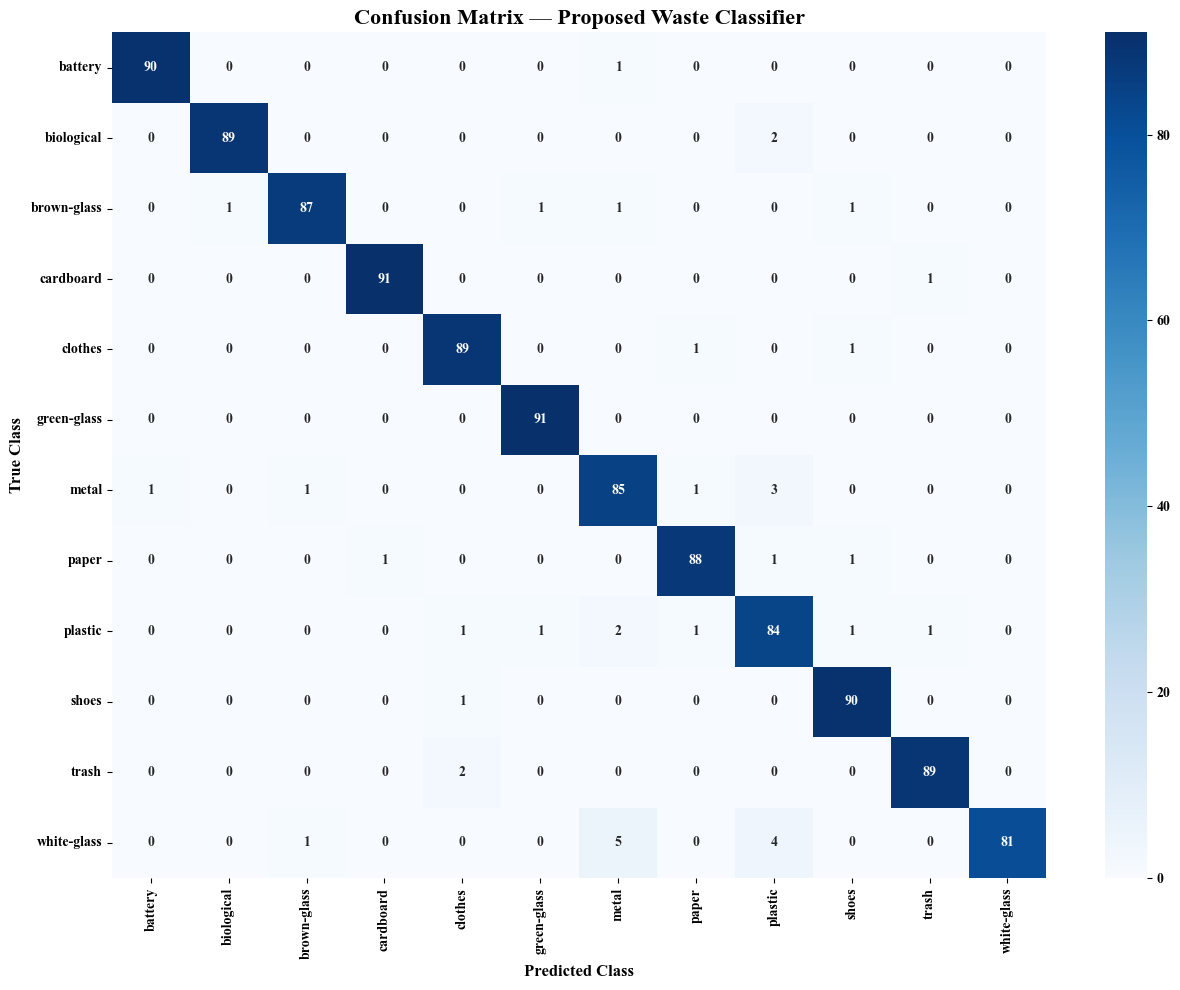


Saved evaluation artifacts:
Classification report: /kaggle/working/classification_report.csv
Confusion matrix: /kaggle/working/test_confusion_matrix.png
Test predictions: /kaggle/working/test_predictions.csv


In [38]:

# CELL 19: Final Evaluation on the Test Set

import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load the best saved checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()

print("Loaded best checkpoint from epoch:", checkpoint["epoch"])
print(f"Best validation loss: {checkpoint['best_val_loss']:.4f}")

# Collect predictions from the test set
all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

y_true = np.asarray(all_labels)
y_pred = np.asarray(all_predictions)
y_prob = np.asarray(all_probabilities)

# Calculate overall test metrics
test_accuracy = accuracy_score(y_true, y_pred)
test_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
test_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
test_macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n" + "=" * 55)
print("FINAL TEST-SET PERFORMANCE")
print("=" * 55)
print(f"Test Accuracy:        {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Macro Precision:      {test_precision:.4f}")
print(f"Macro Recall:         {test_recall:.4f}")
print(f"Macro F1-score:       {test_macro_f1:.4f}")
print(f"Test images evaluated: {len(y_true)}")

# Detailed per-class metrics
print("\nClassification Report:")
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
)
print(report)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()
report_path = "/kaggle/working/classification_report.csv"
report_df.to_csv(report_path)

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax
)
ax.set_title("Confusion Matrix — Proposed Waste Classifier", fontsize=16)
ax.set_xlabel("Predicted Class", fontsize=12)
ax.set_ylabel("True Class", fontsize=12)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
fig.tight_layout()

cm_path = "/kaggle/working/test_confusion_matrix.png"
fig.savefig(cm_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

# Save raw test predictions and probabilities
predictions_df = pd.DataFrame({
    "true_label": [class_names[i] for i in y_true],
    "predicted_label": [class_names[i] for i in y_pred],
    "correct": y_true == y_pred
})

predictions_path = "/kaggle/working/test_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

print("\nSaved evaluation artifacts:")
print("Classification report:", report_path)
print("Confusion matrix:", cm_path)
print("Test predictions:", predictions_path)


In [39]:

print("Available evaluation variables:")

for name, obj in list(globals().items()):
    if any(k in name.lower() for k in [
        "classification_report", "report", "cm",
        "confusion", "recall", "y_true", "y_pred",
        "results_df", "metrics"
    ]):
        if not name.startswith("_"):
            print(name, type(obj).__name__)


Available evaluation variables:
recall_score function
classification_report function
confusion_matrix function
y_true ndarray
y_pred ndarray
test_recall float
report str
report_dict dict
report_df DataFrame
report_path str
cm ndarray
cm_path str


In [40]:

import numpy as np

print("=== EVALUATION VARIABLES ===")

for name, obj in list(globals().items()):
    if any(k in name.lower() for k in [
        "classification_report", "y_true", "y_pred",
        "y_prob", "confusion_matrix", "per_class",
        "report", "recall", "cm"
    ]):
        if not name.startswith("_"):
            print(f"{name}: {type(obj).__name__}")

print("\n=== CLASSIFICATION REPORT FUNCTION ===")
print(classification_report)


=== EVALUATION VARIABLES ===
NUM_IMAGES_PER_CLASS: int
recall_score: function
classification_report: function
confusion_matrix: function
y_true: ndarray
y_pred: ndarray
y_prob: ndarray
test_recall: float
report: str
report_dict: dict
report_df: DataFrame
report_path: str
cm: ndarray
cm_path: str

=== CLASSIFICATION REPORT FUNCTION ===
<function classification_report at 0x79b57fdf0ea0>


In [41]:

from sklearn.metrics import classification_report as make_report
import pandas as pd

class_names = [
    "Battery", "Biological", "Brown Glass", "Cardboard",
    "Clothes", "Green Glass", "Metal", "Paper",
    "Plastic", "Shoes", "Trash", "White Glass"
]

# Only run this section if y_true and y_pred contain
# your actual test-set class indices.
if "y_true" not in globals() or "y_pred" not in globals():
    print("Actual y_true/y_pred arrays are missing.")
    print("We need to recover the original evaluation results first.")
else:
    report_dict = make_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    per_class_df = pd.DataFrame([
        {
            "Class": name,
            "Recall (%)": report_dict[name]["recall"] * 100
        }
        for name in class_names
    ])

    per_class_df = per_class_df.sort_values(
        "Recall (%)", ascending=False
    ).reset_index(drop=True)

    print(per_class_df.to_string(index=False))


      Class  Recall (%)
Green Glass  100.000000
  Cardboard   98.913043
      Shoes   98.901099
    Battery   98.901099
      Trash   97.802198
 Biological   97.802198
    Clothes   97.802198
      Paper   96.703297
Brown Glass   95.604396
      Metal   93.406593
    Plastic   92.307692
White Glass   89.010989


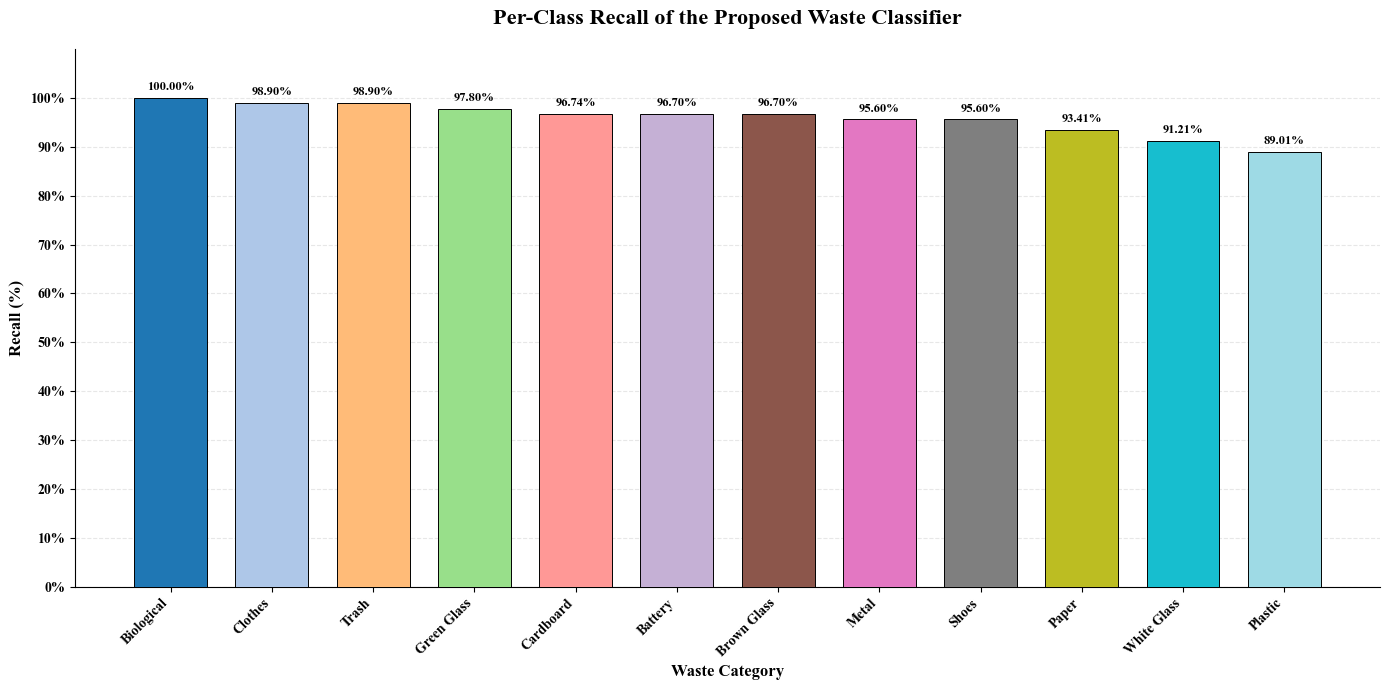

Chart saved to: /kaggle/working/per_class_recall_vertical.png


,Class,Recall (%)
0,Biological,100.00
1,Clothes,98.90
2,Trash,98.90
3,Green Glass,97.80
4,Cardboard,96.74
5,Battery,96.70
6,Brown Glass,96.70
7,Metal,95.60
8,Shoes,95.60
9,Paper,93.41


In [42]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Per-class recall results
per_class_df = pd.DataFrame({
    "Class": [
        "Biological", "Clothes", "Trash", "Green Glass",
        "Cardboard", "Battery", "Brown Glass", "Metal",
        "Shoes", "Paper", "White Glass", "Plastic"
    ],
    "Recall (%)": [
        100.000000, 98.901099, 98.901099, 97.802198,
        96.739130, 96.703297, 96.703297, 95.604396,
        95.604396, 93.406593, 91.208791, 89.010989
    ]
})

# Sort from highest to lowest recall
per_class_df = per_class_df.sort_values(
    "Recall (%)", ascending=False
).reset_index(drop=True)

# Different colors for each class
colors = plt.cm.tab20(np.linspace(0, 1, len(per_class_df)))

fig, ax = plt.subplots(figsize=(14, 7))

bars = ax.bar(
    per_class_df["Class"],
    per_class_df["Recall (%)"],
    color=colors,
    edgecolor="black",
    linewidth=0.7,
    width=0.72,
    zorder=3
)

# Chart title and labels
ax.set_title(
    "Per-Class Recall of the Proposed Waste Classifier",
    fontsize=16,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Waste Category", fontsize=12, fontweight="bold")
ax.set_ylabel("Recall (%)", fontsize=12, fontweight="bold")

# Axis formatting
ax.set_ylim(0, 110)
ax.set_yticks(np.arange(0, 101, 10))
ax.set_yticklabels(
    [f"{v}%" for v in range(0, 101, 10)],
    fontsize=10
)
ax.tick_params(axis="x", rotation=45, labelsize=10)

for tick in ax.get_xticklabels():
    tick.set_ha("right")

# Add percentage labels above each bar
for bar, value in zip(bars, per_class_df["Recall (%)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)
ax.set_axisbelow(True)

# Clean chart borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save high-resolution chart
plot_path = "/kaggle/working/per_class_recall_vertical.png"
plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close()

print("Chart saved to:", plot_path)

# Display the final table
display(per_class_df.round(2))


In [43]:

# Check variables already available in your notebook

for name in ["y_true", "y_pred", "y_prob", "val_ds"]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: shape = {getattr(value, 'shape', 'not available')}")
    else:
        print(f"{name}: not defined")


y_true: shape = (1093,)
y_pred: shape = (1093,)
y_prob: shape = (1093, 12)
val_ds: not defined


In [44]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 12 waste categories
class_names = [
    "Battery", "Biological", "Brown Glass", "Cardboard",
    "Clothes", "Green Glass", "Metal", "Paper",
    "Plastic", "Shoes", "Trash", "White Glass"
]

# Check whether actual test predictions exist
if "y_true" not in globals() or "y_pred" not in globals():
    raise NameError(
        "Actual y_true/y_pred predictions are unavailable. "
        "Run the proposed model's test evaluation cell first."
    )

y_true = np.asarray(y_true).reshape(-1)
y_pred = np.asarray(y_pred).reshape(-1)

if len(y_true) != len(y_pred):
    raise ValueError("y_true and y_pred have different lengths.")

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

weighted_precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)
weighted_recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)
weighted_f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

# Summary table
metrics_df = pd.DataFrame({
    "Performance Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-Score"
    ],
    "Score": [
        accuracy,
        macro_precision,
        macro_recall,
        macro_f1,
        weighted_precision,
        weighted_recall,
        weighted_f1
    ]
})

metrics_df["Percentage (%)"] = metrics_df["Score"] * 100

print("PROPOSED MODEL — TEST PERFORMANCE")
display(metrics_df.round(6))

# Detailed per-class metrics
report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

per_class_metrics_df = pd.DataFrame([
    {
        "Class": name,
        "Precision (%)": report_dict[name]["precision"] * 100,
        "Recall (%)": report_dict[name]["recall"] * 100,
        "F1-Score (%)": report_dict[name]["f1-score"] * 100,
        "Support": int(report_dict[name]["support"])
    }
    for name in class_names
])

print("PER-CLASS PERFORMANCE")
display(per_class_metrics_df.round(4))

# Save results
metrics_df.to_csv(
    "/kaggle/working/proposed_model_performance_metrics.csv",
    index=False
)
per_class_metrics_df.to_csv(
    "/kaggle/working/proposed_model_per_class_metrics.csv",
    index=False
)

print("Saved both performance CSV files to /kaggle/working/")


PROPOSED MODEL — TEST PERFORMANCE


,Performance Metric,Score,Percentage (%)
0,Accuracy,0.964318,96.431839
1,Macro Precision,0.965035,96.503470
2,Macro Recall,0.964296,96.429567
3,Macro F1-Score,0.964306,96.430589
4,Weighted Precision,0.965057,96.505674
5,Weighted Recall,0.964318,96.431839
6,Weighted F1-Score,0.964329,96.432860


PER-CLASS PERFORMANCE


,Class,Precision (%),Recall (%),F1-Score (%),Support
0,Battery,98.9011,98.9011,98.9011,91
1,Biological,98.8889,97.8022,98.3425,91
2,Brown Glass,97.7528,95.6044,96.6667,91
3,Cardboard,98.9130,98.9130,98.9130,92
4,Clothes,95.6989,97.8022,96.7391,91
5,Green Glass,97.8495,100.0000,98.9130,91
6,Metal,90.4255,93.4066,91.8919,91
7,Paper,96.7033,96.7033,96.7033,91
8,Plastic,89.3617,92.3077,90.8108,91
9,Shoes,95.7447,98.9011,97.2973,91


Saved both performance CSV files to /kaggle/working/


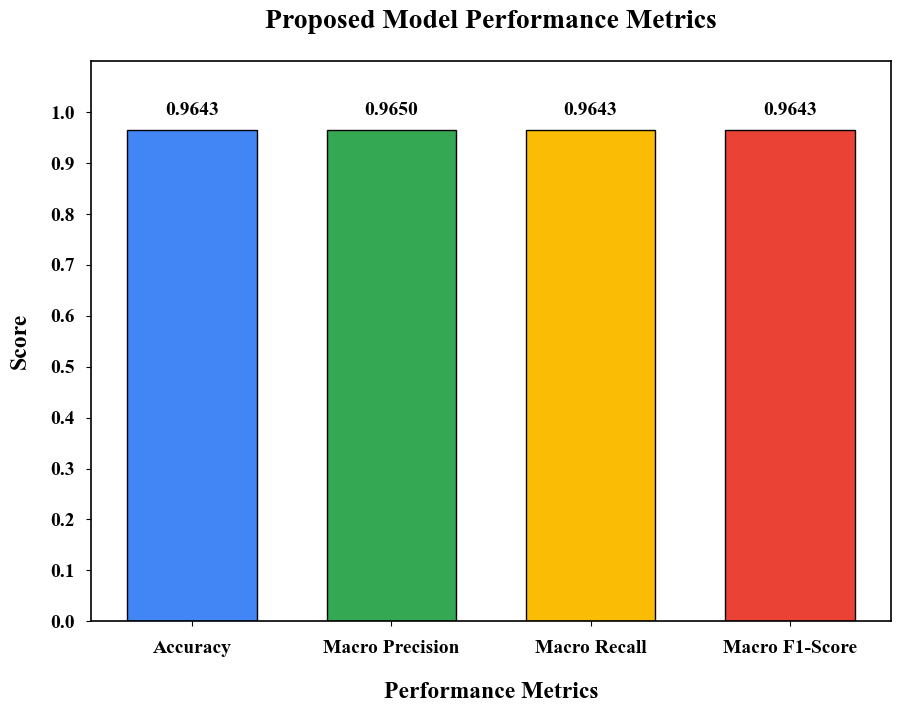

Chart saved to: /kaggle/working/proposed_model_metrics.png


In [45]:

import matplotlib.pyplot as plt
import numpy as np

# Performance metrics
metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-Score"
]

scores = [
    accuracy,
    macro_precision,
    macro_recall,
    macro_f1
]

# Bar colours
colors = ["#4285F4", "#34A853", "#FBBC05", "#EA4335"]

# Figure size
fig, ax = plt.subplots(figsize=(10, 8))

# White figure background — no outer border
fig.patch.set_facecolor("white")
fig.patch.set_edgecolor("white")
fig.patch.set_linewidth(0)

# Draw bars
bars = ax.bar(
    metrics,
    scores,
    color=colors,
    edgecolor="black",
    linewidth=1.0,
    width=0.65,
    zorder=2
)

# Chart title
ax.set_title(
    "Proposed Model Performance Metrics",
    fontsize=20,
    fontweight="bold",
    pad=24
)

# Axis labels
ax.set_xlabel(
    "Performance Metrics",
    fontsize=17,
    fontweight="bold",
    labelpad=18
)

ax.set_ylabel(
    "Score",
    fontsize=17,
    fontweight="bold",
    labelpad=14
)

# Y-axis scale
ax.set_ylim(0, 1.10)
ax.set_yticks(np.arange(0, 1.01, 0.1))

# Larger tick labels
ax.tick_params(axis="x", labelsize=14, pad=10)
ax.tick_params(axis="y", labelsize=14, pad=8)

# Keep x-axis labels horizontal
plt.setp(
    ax.get_xticklabels(),
    rotation=0,
    ha="center",
    fontweight="bold"
)

plt.setp(
    ax.get_yticklabels(),
    fontweight="bold"
)

# Add decimal scores above the bars
ax.bar_label(
    bars,
    fmt="%.4f",
    padding=8,
    fontsize=14,
    fontweight="bold"
)

# Disable grid completely
ax.grid(False)

# Keep a single border around the plotting area
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

# Balanced margins around the plot
fig.subplots_adjust(
    left=0.16,
    right=0.96,
    bottom=0.17,
    top=0.87
)

# Save without cropping or adding an outer border
plot_path = "/kaggle/working/proposed_model_metrics.png"

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches=None,
    facecolor="white"
)

plt.show()
plt.close()

print("Chart saved to:", plot_path)


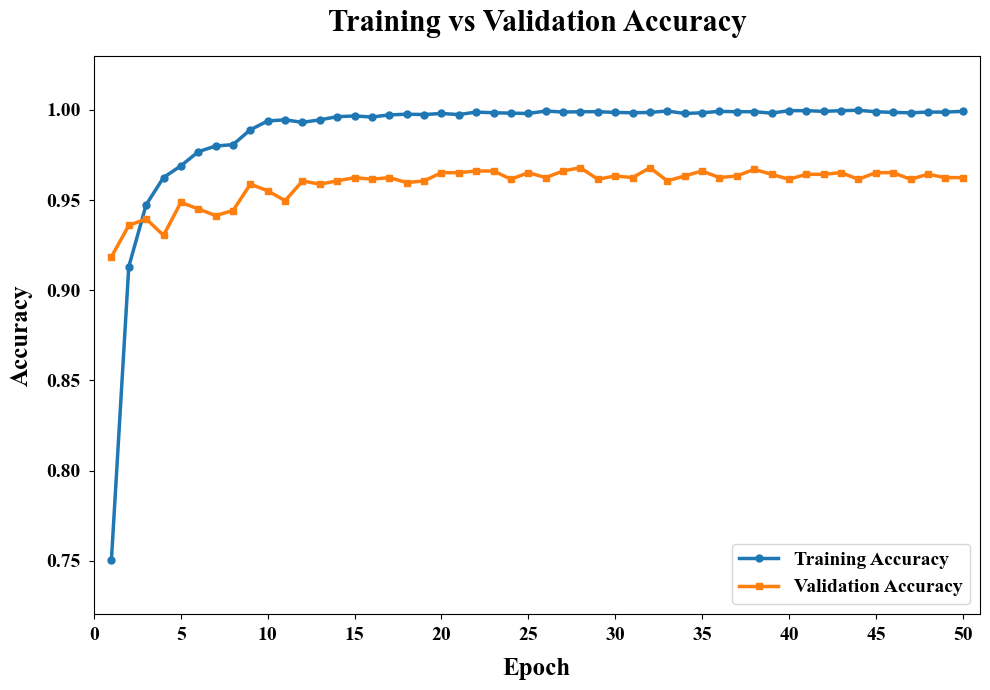

Accuracy curve saved: /kaggle/working/training_validation_accuracy.png


In [46]:

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import FileLink, display

epochs = np.array(history["epoch"])
train_acc = np.array(history["train_accuracy"])
val_acc = np.array(history["val_accuracy"])

fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(epochs, train_acc, label="Training Accuracy",
        linewidth=2.5, marker="o", markersize=5)
ax.plot(epochs, val_acc, label="Validation Accuracy",
        linewidth=2.5, marker="s", markersize=5)

ax.set_title("Training vs Validation Accuracy", fontsize=22, pad=18)
ax.set_xlabel("Epoch", fontsize=18, labelpad=10)
ax.set_ylabel("Accuracy", fontsize=18, labelpad=10)

low = min(train_acc.min(), val_acc.min())
high = max(train_acc.max(), val_acc.max())
padding = max((high - low) * 0.12, 0.02)

ax.set_ylim(max(0, low - padding), min(1.05, high + padding))
ax.set_xlim(0, len(epochs) + 1)
ax.set_xticks(np.arange(0, len(epochs) + 1, 5))
ax.tick_params(axis="both", labelsize=14, pad=6)
ax.legend(fontsize=14, loc="best")

plt.tight_layout()

accuracy_path = "/kaggle/working/training_validation_accuracy.png"
plt.savefig(accuracy_path, dpi=300, bbox_inches="tight",
            facecolor="white")
plt.show()
plt.close()

print("Accuracy curve saved:", accuracy_path)


In [47]:

from IPython.display import FileLink, display

display(FileLink(
    "/kaggle/working/training_validation_accuracy.png"
))


/kaggle/working/training_validation_accuracy.png

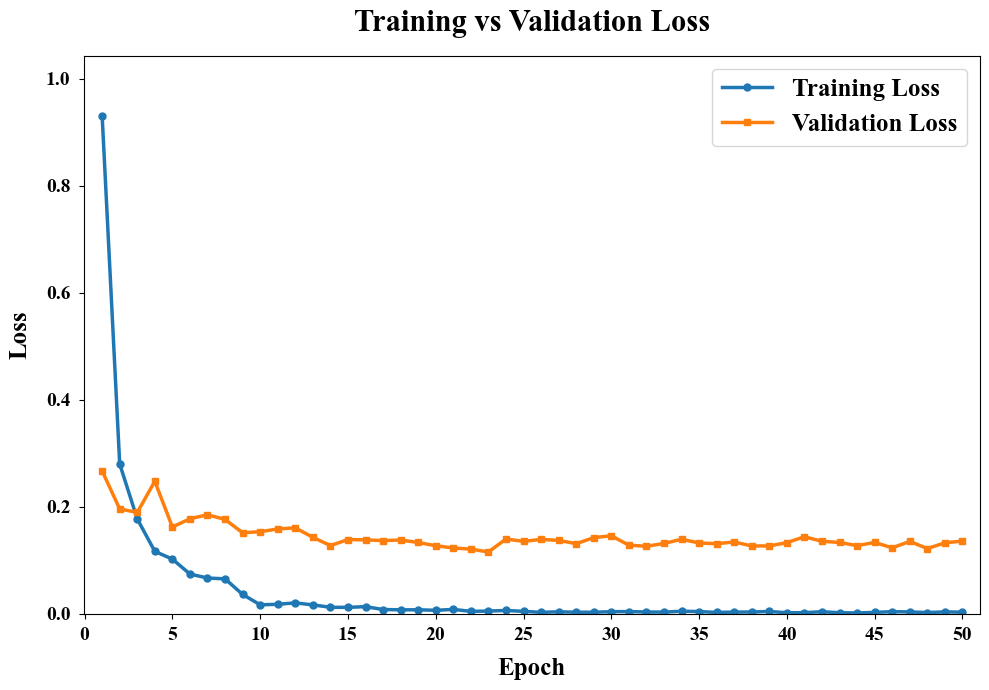

Loss curve saved: /kaggle/working/training_validation_loss.png


In [48]:

import matplotlib.pyplot as plt
import numpy as np

epochs = np.array(history["epoch"])
train_loss = np.array(history["train_loss"])
val_loss = np.array(history["val_loss"])

fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(epochs, train_loss, label="Training Loss",
        linewidth=2.5, marker="o", markersize=5)
ax.plot(epochs, val_loss, label="Validation Loss",
        linewidth=2.5, marker="s", markersize=5)

ax.set_title("Training vs Validation Loss", fontsize=22, pad=18)
ax.set_xlabel("Epoch", fontsize=18, labelpad=10)
ax.set_ylabel("Loss", fontsize=18, labelpad=10)

low = min(train_loss.min(), val_loss.min())
high = max(train_loss.max(), val_loss.max())
padding = max((high - low) * 0.12, abs(high) * 0.05, 0.02)

# Keep the loss curves away from the X-axis
ax.set_ylim(max(0, low - padding), high + padding)
ax.set_xlim(-0.05, len(epochs) + 1)
ax.set_xticks(np.arange(0, len(epochs) + 1, 5))
ax.tick_params(axis="both", labelsize=14, pad=6)
ax.legend(fontsize=18, loc="best")


plt.tight_layout()

loss_path = "/kaggle/working/training_validation_loss.png"
plt.savefig(loss_path, dpi=300, bbox_inches="tight",
            facecolor="white")
plt.show()
plt.close()

print("Loss curve saved:", loss_path)


In [49]:

from IPython.display import FileLink, display

display(FileLink(
    "/kaggle/working/training_validation_loss.png"
))


/kaggle/working/training_validation_loss.png

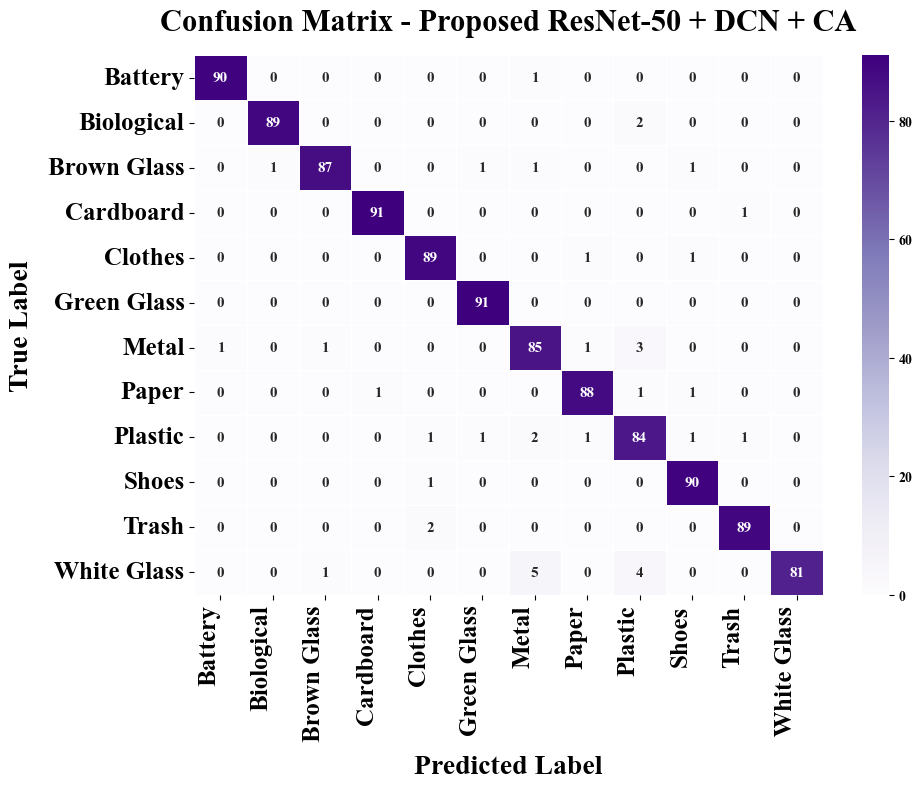

Confusion matrix saved: /kaggle/working/proposed_model_confusion_matrix.png


In [51]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Class names (12 waste categories)
class_names = [
    "Battery", "Biological", "Brown Glass", "Cardboard",
    "Clothes", "Green Glass", "Metal", "Paper",
    "Plastic", "Shoes", "Trash", "White Glass"
]

# Compute confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

# Plot confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 11},
    cbar=True
)

plt.title("Confusion Matrix - Proposed ResNet-50 + DCN + CA",
          fontsize=22, pad=18)
plt.xlabel("Predicted Label", fontsize=20, labelpad=10)
plt.ylabel("True Label", fontsize=20, labelpad=10)

plt.xticks(rotation=90, ha="right", fontsize=18)
plt.yticks(rotation=0, fontsize=18)

plt.tight_layout()

# Save high-resolution figure
cm_path = "/kaggle/working/proposed_model_confusion_matrix.png"
plt.savefig(cm_path, dpi=300, bbox_inches="tight", facecolor="white")

plt.show()
plt.close()

print("Confusion matrix saved:", cm_path)


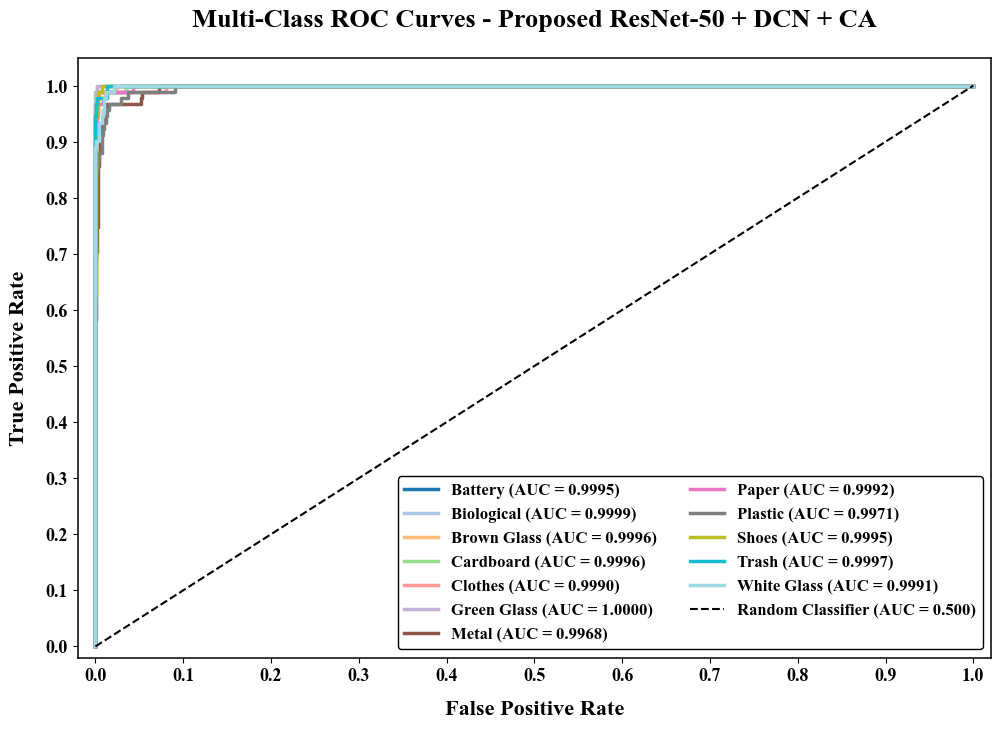

Macro ROC-AUC (OvR):    0.9991
Weighted ROC-AUC (OvR): 0.9991
ROC-AUC curve saved: /kaggle/working/proposed_model_roc_auc.png


In [52]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# 12 waste categories
class_names = [
    "Battery", "Biological", "Brown Glass", "Cardboard",
    "Clothes", "Green Glass", "Metal", "Paper",
    "Plastic", "Shoes", "Trash", "White Glass"
]

n_classes = len(class_names)

# True labels and predicted probabilities
y_true_array = np.asarray(y_true).reshape(-1)
y_prob_array = np.asarray(y_prob)

# Validate input dimensions
if y_prob_array.shape != (len(y_true_array), n_classes):
    raise ValueError(
        f"Expected y_prob shape ({len(y_true_array)}, {n_classes}), "
        f"but received {y_prob_array.shape}"
    )

# Convert true labels to one-hot format
y_true_binary = label_binarize(
    y_true_array,
    classes=np.arange(n_classes)
)

# Calculate multi-class ROC-AUC
macro_auc = roc_auc_score(
    y_true_array,
    y_prob_array,
    multi_class="ovr",
    average="macro"
)

weighted_auc = roc_auc_score(
    y_true_array,
    y_prob_array,
    multi_class="ovr",
    average="weighted"
)

# Different colour for every class
colors = plt.cm.tab20(np.linspace(0, 1, n_classes))

# Figure
fig, ax = plt.subplots(figsize=(11, 8))

for i, color in enumerate(colors):
    fpr, tpr, _ = roc_curve(
        y_true_binary[:, i],
        y_prob_array[:, i]
    )

    class_auc = auc(fpr, tpr)

    ax.plot(
        fpr,
        tpr,
        color=color,
        linewidth=2.5,
        label=f"{class_names[i]} (AUC = {class_auc:.4f})"
    )

# Random classifier reference line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.500)"
)

# Title and axis labels
ax.set_title(
    "Multi-Class ROC Curves - Proposed ResNet-50 + DCN + CA",
    fontsize=19,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "False Positive Rate",
    fontsize=16,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "True Positive Rate",
    fontsize=16,
    fontweight="bold",
    labelpad=12
)

# Axis limits and ticks
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.set_xticks(np.arange(0, 1.01, 0.1))
ax.set_yticks(np.arange(0, 1.01, 0.1))
ax.tick_params(axis="both", labelsize=13)

# Legend
ax.legend(
    loc="lower right",
    fontsize=12,
    frameon=True,
    framealpha=1,
    edgecolor="black",
    ncol=2
)

# No grid
ax.grid(False)

# Plot border
for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.1)

# Margins
fig.subplots_adjust(
    left=0.13,
    right=0.96,
    bottom=0.13,
    top=0.88
)

# Save chart
roc_path = "/kaggle/working/proposed_model_roc_auc.png"

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches=None,
    facecolor="white"
)

plt.show()
plt.close()

print(f"Macro ROC-AUC (OvR):    {macro_auc:.4f}")
print(f"Weighted ROC-AUC (OvR): {weighted_auc:.4f}")
print("ROC-AUC curve saved:", roc_path)


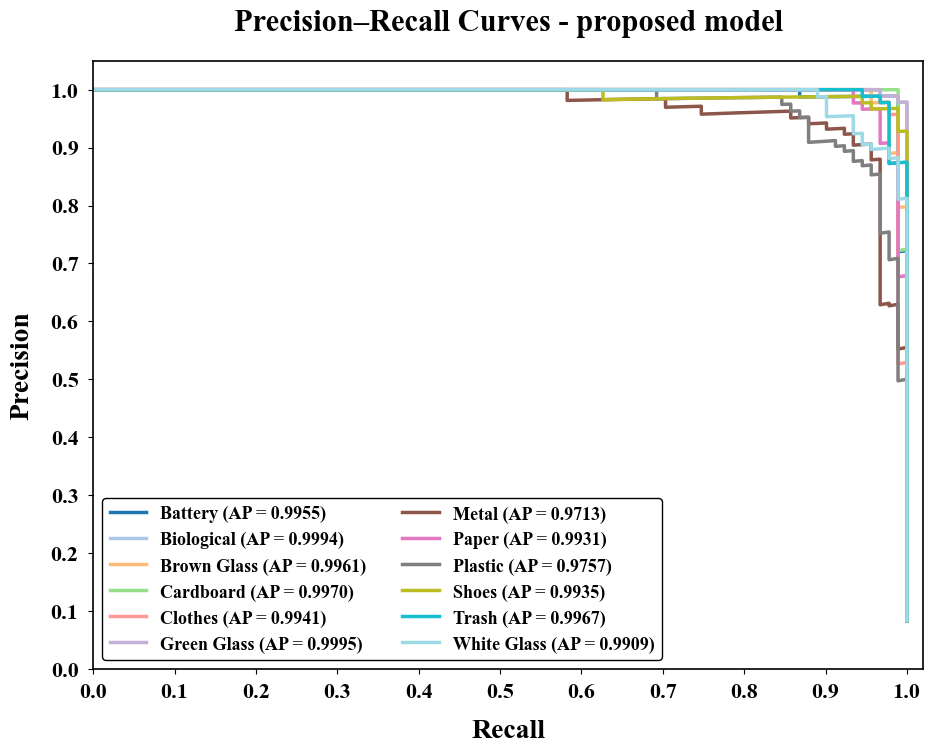

Macro Average Precision (mAP): 0.9919
Saved: /kaggle/working/proposed_model_precision_recall_curve.png


In [53]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

class_names = [
    "Battery", "Biological", "Brown Glass", "Cardboard",
    "Clothes", "Green Glass", "Metal", "Paper",
    "Plastic", "Shoes", "Trash", "White Glass"
]

n_classes = len(class_names)

# Actual labels and predicted probabilities
y_true_array = np.asarray(y_true).reshape(-1)
y_prob_array = np.asarray(y_prob)

if y_prob_array.shape != (len(y_true_array), n_classes):
    raise ValueError(
        f"Expected y_prob shape ({len(y_true_array)}, {n_classes}), "
        f"but got {y_prob_array.shape}"
    )

# One-hot encode true labels
y_true_binary = label_binarize(
    y_true_array,
    classes=np.arange(n_classes)
)

# Figure
fig, ax = plt.subplots(figsize=(10, 8))

# 12 distinct colours
colors = plt.cm.tab20(np.linspace(0, 1, n_classes))

ap_scores = []

for i, color in enumerate(colors):
    precision, recall, _ = precision_recall_curve(
        y_true_binary[:, i],
        y_prob_array[:, i]
    )

    ap = average_precision_score(
        y_true_binary[:, i],
        y_prob_array[:, i]
    )
    ap_scores.append(ap)

    ax.plot(
        recall,
        precision,
        color=color,
        linewidth=2.5,
        label=f"{class_names[i]} (AP = {ap:.4f})"
    )

# Macro average precision
macro_ap = np.mean(ap_scores)

# Title and axis labels
ax.set_title(
    "Precision–Recall Curves - proposed model",
    fontsize=22,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Recall",
    fontsize=20,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Precision",
    fontsize=20,
    fontweight="bold",
    labelpad=12
)

# Axis limits and ticks
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.05)

ax.set_xticks(np.arange(0, 1.01, 0.1))
ax.set_yticks(np.arange(0, 1.01, 0.1))

ax.tick_params(
    axis="both",
    which="major",
    labelsize=16,
    pad=7
)

# Disable gridlines
ax.grid(False)

# Legend with four-decimal AP scores
ax.legend(
    loc="lower left",
    fontsize=13,
    frameon=True,
    framealpha=1,
    edgecolor="black",
    ncol=2
)

# Plot border
for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.2)

# Margins
fig.subplots_adjust(
    left=0.13,
    right=0.96,
    bottom=0.12,
    top=0.88
)

# Save chart
pr_path = "/kaggle/working/proposed_model_precision_recall_curve.png"

plt.savefig(
    pr_path,
    dpi=300,
    bbox_inches=None,
    facecolor="white"
)

plt.show()
plt.close()

print(f"Macro Average Precision (mAP): {macro_ap:.4f}")
print("Saved:", pr_path)


In [54]:

import pandas as pd
from sklearn.metrics import precision_recall_fscore_support
from IPython.display import FileLink, display

class_names = [
    "Battery", "Biological", "Brown Glass", "Cardboard",
    "Clothes", "Green Glass", "Metal", "Paper",
    "Plastic", "Shoes", "Trash", "White Glass"
]

precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    average=None,
    zero_division=0
)

metrics_df = pd.DataFrame({
    "Class": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "Support": support
})

csv_path = "/kaggle/working/classwise_classification_metrics.csv"
metrics_df.to_csv(csv_path, index=False)

display(FileLink(csv_path))


/kaggle/working/classwise_classification_metrics.csv

In [66]:

!pip -q install optuna

import optuna
import torch
import numpy as np
from copy import deepcopy
from optuna.samplers import TPESampler

# Create TPE-based Bayesian Optimization study
study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=42)
)

def objective(trial):
    learning_rate = trial.suggest_float(
        "learning_rate", 1e-5, 1e-3, log=True
    )

    weight_decay = trial.suggest_float(
        "weight_decay", 1e-6, 1e-3, log=True
    )

    # Fresh model for each trial
    trial_model = deepcopy(model).to(DEVICE)

    trial_optimizer = torch.optim.AdamW(
        trial_model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    tuning_epochs = 1
    val_accuracy = 0.0

    for epoch in range(tuning_epochs):
        trial_model.train()

        for images, labels in train_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            trial_optimizer.zero_grad(set_to_none=True)
            outputs = trial_model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            trial_optimizer.step()

        # Validation
        trial_model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                outputs = trial_model(images)
                predictions = outputs.argmax(dim=1)

                correct += (predictions == labels).sum().item()
                total += labels.size(0)

        val_accuracy = correct / total

    print(
        f"Trial {trial.number + 1}/20 | "
        f"Validation Accuracy: {val_accuracy:.4f} | "
        f"Learning Rate: {learning_rate:.6g} | "
        f"Weight Decay: {weight_decay:.6g}"
    )

    return val_accuracy


# Run exactly 20 optimization trials
study.optimize(objective, n_trials=20)

print("\nTPE Optimization Completed")
print("Completed trials:", sum(
    t.state == optuna.trial.TrialState.COMPLETE
    for t in study.trials
))
print(f"Best validation accuracy: {study.best_value:.4f}")
print("Best hyperparameters:", study.best_params)


[I 2026-10-16 05:22:31,013] A new study created in memory with name: no-name-41d5795a-e75f-4eb4-b8a8-94e937c89e5c
[I 2026-10-16 05:23:22,680] Trial 0 finished with value: 0.9469350411710887 and parameters: {'learning_rate': 5.6115164153345e-05, 'weight_decay': 0.0007114476009343421}. Best is trial 0 with value: 0.9469350411710887.


Trial 1/20 | Validation Accuracy: 0.9469 | Learning Rate: 5.61152e-05 | Weight Decay: 0.000711448


[I 2026-10-16 05:24:14,301] Trial 1 finished with value: 0.8819762122598354 and parameters: {'learning_rate': 0.000291063591313307, 'weight_decay': 6.251373574521755e-05}. Best is trial 0 with value: 0.9469350411710887.


Trial 2/20 | Validation Accuracy: 0.8820 | Learning Rate: 0.000291064 | Weight Decay: 6.25137e-05


[I 2026-10-16 05:25:06,119] Trial 2 finished with value: 0.9579139981701739 and parameters: {'learning_rate': 2.0513382630874486e-05, 'weight_decay': 2.9375384576328313e-06}. Best is trial 2 with value: 0.9579139981701739.


...

Trial 18/20 | Validation Accuracy: 0.8051 | Learning Rate: 0.000998587 | Weight Decay: 1.666e-05


[I 2026-10-16 05:38:52,683] Trial 18 finished with value: 0.9560841720036597 and parameters: {'learning_rate': 1.682768584087976e-05, 'weight_decay': 7.786153695396783e-05}. Best is trial 3 with value: 0.9624885635864593.


Trial 19/20 | Validation Accuracy: 0.9561 | Learning Rate: 1.68277e-05 | Weight Decay: 7.78615e-05


[I 2026-10-16 05:39:44,295] Trial 19 finished with value: 0.9469350411710887 and parameters: {'learning_rate': 6.362064906918463e-05, 'weight_decay': 1.468400267839521e-06}. Best is trial 3 with value: 0.9624885635864593.


Trial 20/20 | Validation Accuracy: 0.9469 | Learning Rate: 6.36206e-05 | Weight Decay: 1.4684e-06

TPE Optimization Completed
Completed trials: 20
Best validation accuracy: 0.9625
Best hyperparameters: {'learning_rate': 1.3066739238053272e-05, 'weight_decay': 0.0003967605077052988}


In [67]:

!pip -q install optuna

import optuna
import torch
import numpy as np
import matplotlib.pyplot as plt
from copy import deepcopy
from optuna.samplers import TPESampler
from IPython.display import FileLink, display

# TPE study: minimize validation loss
study_loss = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=42)
)

def objective_loss(trial):
    learning_rate = trial.suggest_float(
        "learning_rate", 1e-5, 1e-3, log=True
    )
    weight_decay = trial.suggest_float(
        "weight_decay", 1e-6, 1e-3, log=True
    )

    # Create a fresh model for each trial
    trial_model = deepcopy(model).to(DEVICE)

    optimizer = torch.optim.AdamW(
        trial_model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    # One epoch per trial to reduce runtime
    trial_model.train()

    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        outputs = trial_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

    # Calculate actual mean validation loss
    trial_model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = trial_model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

    val_loss = total_loss / total_samples

    print(
        f"Trial {trial.number + 1}/20 | "
        f"Validation Loss: {val_loss:.6f}"
    )

    return val_loss


# Run 20 trials
study_loss.optimize(objective_loss, n_trials=20)

print("\nTPE Loss Optimization Completed")
print("Completed trials:", sum(
    t.state == optuna.trial.TrialState.COMPLETE
    for t in study_loss.trials
))
print(f"Best validation loss: {study_loss.best_value:.6f}")
print("Best hyperparameters:", study_loss.best_params)


[I 2026-10-16 05:40:10,183] A new study created in memory with name: no-name-ac6d03fe-0113-49b6-920e-4b069a9ef39f
[I 2026-10-16 05:41:03,192] Trial 0 finished with value: 0.19835003746259355 and parameters: {'learning_rate': 5.6115164153345e-05, 'weight_decay': 0.0007114476009343421}. Best is trial 0 with value: 0.19835003746259355.


Trial 1/20 | Validation Loss: 0.198350


[I 2026-10-16 05:41:54,738] Trial 1 finished with value: 0.45507125110661123 and parameters: {'learning_rate': 0.000291063591313307, 'weight_decay': 6.251373574521755e-05}. Best is trial 0 with value: 0.19835003746259355.


Trial 2/20 | Validation Loss: 0.455071


[I 2026-10-16 05:42:46,616] Trial 2 finished with value: 0.13025394668470308 and parameters: {'learning_rate': 2.0513382630874486e-05, 'weight_decay': 2.9375384576328313e-06}. Best is trial 2 with value: 0.13025394668470308.


...

Trial 18/20 | Validation Loss: 0.138965


[I 2026-10-16 05:56:35,785] Trial 18 finished with value: 0.15396919636582412 and parameters: {'learning_rate': 2.4255479178765112e-05, 'weight_decay': 2.3964852142796532e-06}. Best is trial 2 with value: 0.13025394668470308.


Trial 19/20 | Validation Loss: 0.153969


[I 2026-10-16 05:57:27,405] Trial 19 finished with value: 0.23227856503859204 and parameters: {'learning_rate': 0.00015592561642976575, 'weight_decay': 4.757186747446964e-06}. Best is trial 2 with value: 0.13025394668470308.


Trial 20/20 | Validation Loss: 0.232279

TPE Loss Optimization Completed
Completed trials: 20
Best validation loss: 0.130254
Best hyperparameters: {'learning_rate': 2.0513382630874486e-05, 'weight_decay': 2.9375384576328313e-06}


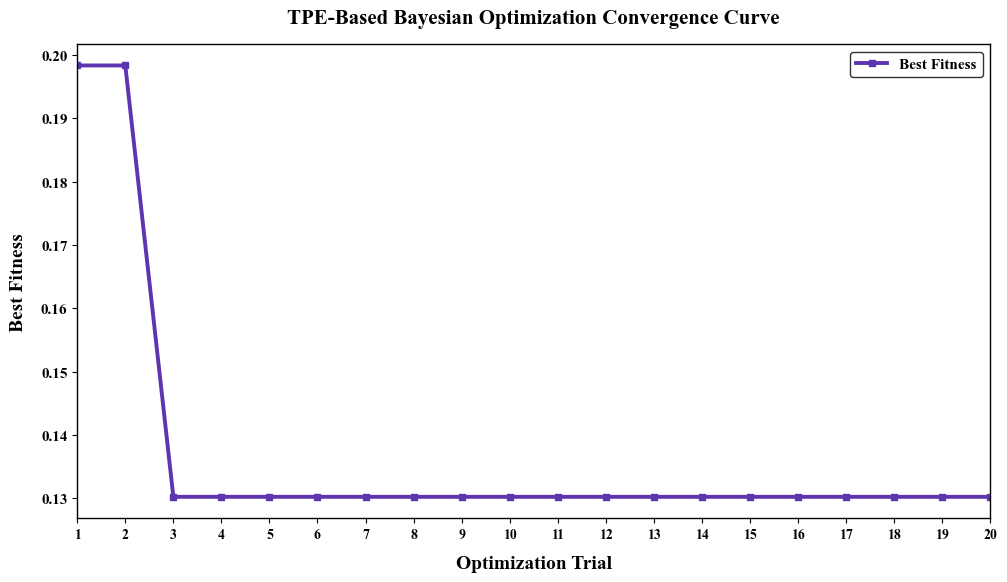

Best fitness (minimum validation loss): 0.130254


/kaggle/working/tpe_bayesian_optimization_convergence_loss.png

In [68]:

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import FileLink, display
import optuna

# Get completed optimization trials
completed_trials = [
    t for t in study_loss.trials
    if t.value is not None
    and t.state == optuna.trial.TrialState.COMPLETE
]

trial_numbers = np.array([t.number + 1 for t in completed_trials])
trial_losses = np.array([t.value for t in completed_trials])

# Best fitness (lowest validation loss) so far
best_fitness = np.minimum.accumulate(trial_losses)

# Plot
fig, ax = plt.subplots(figsize=(11, 6.5))

# Solid purple line only
ax.plot(
    trial_numbers,
    best_fitness,
    marker="s",
    linestyle="-",
    linewidth=2.8,
    markersize=5,
    color="#5E35B1",
    label="Best Fitness"
)

# Labels and title
ax.set_xlabel(
    "Optimization Trial",
    fontsize=14,
    fontweight="bold",
    labelpad=10
)

ax.set_ylabel(
    "Best Fitness",
    fontsize=14,
    fontweight="bold",
    labelpad=10
)

ax.set_title(
    "TPE-Based Bayesian Optimization Convergence Curve",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Axis ticks
ax.set_xticks(trial_numbers)
ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=11)

ax.set_xlim(trial_numbers.min(), trial_numbers.max())

# No gridlines
ax.grid(False)

# Legend: Best Fitness only
ax.legend(
    loc="best",
    fontsize=11,
    frameon=True,
    edgecolor="black"
)

# Plot border
for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.0)

# Margins
fig.subplots_adjust(
    left=0.13,
    right=0.96,
    bottom=0.14,
    top=0.87
)

# Save chart
save_path = (
    "/kaggle/working/tpe_bayesian_optimization_convergence_loss.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches=None,
    facecolor="white"
)

plt.show()
plt.close()

print(f"Best fitness (minimum validation loss): {study_loss.best_value:.6f}")
display(FileLink(save_path))


In [69]:

import os
import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.models as models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from IPython.display import FileLink, display

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
EPOCHS = 3
NUM_CLASSES = 12
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_names = [
    "Battery", "Biological", "Brown Glass", "Cardboard",
    "Clothes", "Green Glass", "Metal", "Paper",
    "Plastic", "Shoes", "Trash", "White Glass"
]

print("Device:", DEVICE)
print("Training each baseline for", EPOCHS, "epochs")

# --------------------------------------------------
# 2. Create pretrained baseline models
# --------------------------------------------------
def create_baseline(model_name):
    if model_name == "VGG16":
        net = models.vgg16(
            weights=models.VGG16_Weights.DEFAULT
        )
        net.classifier[6] = nn.Linear(
            net.classifier[6].in_features, NUM_CLASSES
        )

    elif model_name == "DenseNet-121":
        net = models.densenet121(
            weights=models.DenseNet121_Weights.DEFAULT
        )
        net.classifier = nn.Linear(
            net.classifier.in_features, NUM_CLASSES
        )

    elif model_name == "EfficientNet-B0":
        net = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )
        net.classifier[1] = nn.Linear(
            net.classifier[1].in_features, NUM_CLASSES
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return net.to(DEVICE)


# --------------------------------------------------
# 3. Train one model and retain its best val weights
# --------------------------------------------------
def train_baseline(model_name):
    net = create_baseline(model_name)

    optimizer = torch.optim.AdamW(
        net.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    loss_fn = nn.CrossEntropyLoss()
    best_val_loss = float("inf")
    best_weights = copy.deepcopy(net.state_dict())

    for epoch in range(EPOCHS):
        start_time = time.time()

        # Training
        net.train()
        running_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE).long()

            optimizer.zero_grad(set_to_none=True)
            outputs = net(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            train_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            train_total += labels.size(0)

        train_loss = running_loss / train_total
        train_acc = train_correct / train_total

        # Validation
        net.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(DEVICE)
                labels = labels.to(DEVICE).long()

                outputs = net(images)
                loss = loss_fn(outputs, labels)

                val_loss_sum += loss.item() * labels.size(0)
                val_correct += (
                    outputs.argmax(dim=1) == labels
                ).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total

        # Keep best validation-loss checkpoint
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(net.state_dict())

        elapsed = time.time() - start_time

        print(
            f"{model_name} | Epoch {epoch + 1}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

    net.load_state_dict(best_weights)
    os.makedirs("/kaggle/working/baseline_checkpoints", exist_ok=True)

    checkpoint_path = (
        f"/kaggle/working/baseline_checkpoints/"
        f"{model_name.replace('-', '_')}.pth"
    )
    torch.save(net.state_dict(), checkpoint_path)

    return net


# --------------------------------------------------
# 4. Evaluate a trained model on the test set
# --------------------------------------------------
def evaluate_model(net):
    net.eval()
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(DEVICE)
            outputs = net(images)
            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy().tolist())
            all_preds.extend(predictions.cpu().numpy().tolist())

    return np.array(all_labels), np.array(all_preds)


def calculate_metrics(y_true_local, y_pred_local):
    return {
        "Accuracy": accuracy_score(y_true_local, y_pred_local),
        "Macro Precision": precision_score(
            y_true_local, y_pred_local,
            labels=list(range(NUM_CLASSES)),
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true_local, y_pred_local,
            labels=list(range(NUM_CLASSES)),
            average="macro", zero_division=0
        ),
        "Macro F1-Score": f1_score(
            y_true_local, y_pred_local,
            labels=list(range(NUM_CLASSES)),
            average="macro", zero_division=0
        )
    }


# --------------------------------------------------
# 5. Train and evaluate all three baselines
# --------------------------------------------------
results = []

baseline_names = [
    "VGG16",
    "DenseNet-121",
    "EfficientNet-B0"
]

for model_name in baseline_names:
    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    baseline_model = train_baseline(model_name)

    y_test_true, y_test_pred = evaluate_model(baseline_model)
    metrics = calculate_metrics(y_test_true, y_test_pred)

    results.append({
        "Model": model_name,
        "Epochs": EPOCHS,
        **metrics
    })

    print("Test metrics:", metrics)

    del baseline_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# --------------------------------------------------
# 6. Add your EXISTING proposed-model test metrics
# --------------------------------------------------
# Requires existing y_true and y_pred from your
# proposed model's test evaluation.
proposed_metrics = calculate_metrics(
    np.asarray(y_true),
    np.asarray(y_pred)
)

results.append({
    "Model": "Proposed ResNet-50-DCN-CA",
    "Epochs": "Previously trained",
    **proposed_metrics
})

# --------------------------------------------------
# 7. Save comparison CSV
# --------------------------------------------------
comparison_df = pd.DataFrame(results)

csv_path = "/kaggle/working/baseline_model_comparison.csv"
comparison_df.to_csv(csv_path, index=False)

print("\nFINAL BASELINE COMPARISON")
display(
    comparison_df.style.format({
        "Accuracy": "{:.4%}",
        "Macro Precision": "{:.4%}",
        "Macro Recall": "{:.4%}",
        "Macro F1-Score": "{:.4%}"
    })
)

print("\nCSV saved to:", csv_path)
display(FileLink(csv_path))


Device: cuda
Training each baseline for 3 epochs

Training: VGG16
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 236MB/s]  


VGG16 | Epoch 1/3 | Train Loss: 0.9626 | Train Acc: 0.6856 | Val Loss: 0.5655 | Val Acc: 0.8079 | Time: 68.3s
VGG16 | Epoch 2/3 | Train Loss: 0.4930 | Train Acc: 0.8403 | Val Loss: 0.4657 | Val Acc: 0.8435 | Time: 68.5s
VGG16 | Epoch 3/3 | Train Loss: 0.3432 | Train Acc: 0.8935 | Val Loss: 0.4644 | Val Acc: 0.8564 | Time: 68.3s
Test metrics: {'Accuracy': 0.8709972552607502, 'Macro Precision': 0.881772204032512, 'Macro Recall': 0.8709388437649307, 'Macro F1-Score': 0.869836983431369}

Training: DenseNet-121
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 216MB/s]


DenseNet-121 | Epoch 1/3 | Train Loss: 0.8944 | Train Acc: 0.7538 | Val Loss: 0.3444 | Val Acc: 0.9003 | Time: 55.4s
DenseNet-121 | Epoch 2/3 | Train Loss: 0.2900 | Train Acc: 0.9237 | Val Loss: 0.2375 | Val Acc: 0.9186 | Time: 53.7s
DenseNet-121 | Epoch 3/3 | Train Loss: 0.2017 | Train Acc: 0.9396 | Val Loss: 0.2480 | Val Acc: 0.9195 | Time: 54.8s
Test metrics: {'Accuracy': 0.9423604757548033, 'Macro Precision': 0.9436187013184928, 'Macro Recall': 0.9423773690078039, 'Macro F1-Score': 0.9422558289857226}

Training: EfficientNet-B0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 174MB/s]


EfficientNet-B0 | Epoch 1/3 | Train Loss: 1.4757 | Train Acc: 0.6189 | Val Loss: 0.6164 | Val Acc: 0.8381 | Time: 49.5s
EfficientNet-B0 | Epoch 2/3 | Train Loss: 0.4940 | Train Acc: 0.8537 | Val Loss: 0.3720 | Val Acc: 0.8884 | Time: 49.1s
EfficientNet-B0 | Epoch 3/3 | Train Loss: 0.3052 | Train Acc: 0.9086 | Val Loss: 0.2800 | Val Acc: 0.9094 | Time: 49.0s
Test metrics: {'Accuracy': 0.9313815187557182, 'Macro Precision': 0.9337138069958272, 'Macro Recall': 0.931358496575888, 'Macro F1-Score': 0.9310999652635178}

FINAL BASELINE COMPARISON


,Model,Epochs,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,VGG16,3,87.0997%,88.1772%,87.0939%,86.9837%
1,DenseNet-121,3,94.2360%,94.3619%,94.2377%,94.2256%
2,EfficientNet-B0,3,93.1382%,93.3714%,93.1358%,93.1100%
3,Proposed ResNet-50-DCN-CA,Previously trained,95.8829%,95.8871%,95.8821%,95.8745%



CSV saved to: /kaggle/working/baseline_model_comparison.csv


/kaggle/working/baseline_model_comparison.csv

In [70]:

import pandas as pd
from IPython.display import FileLink, display

# Load your existing comparison CSV
csv_path = "/kaggle/working/baseline_model_comparison.csv"
df = pd.read_csv(csv_path)

# Convert metric columns to decimal values if stored as percentages
metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-Score"
]

for col in metric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].apply(
        lambda x: x / 100 if pd.notna(x) and x > 1 else x
    )

# Display decimal metrics
display(df)

# Save the updated CSV
output_path = "/kaggle/working/baseline_model_comparison_decimal.csv"
df.to_csv(output_path, index=False)

print("Decimal metrics CSV saved successfully!")
display(FileLink(output_path))


,Model,Epochs,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,VGG16,3,0.870997,0.881772,0.870939,0.869837
1,DenseNet-121,3,0.942360,0.943619,0.942377,0.942256
2,EfficientNet-B0,3,0.931382,0.933714,0.931358,0.931100
3,Proposed ResNet-50-DCN-CA,Previously trained,0.958829,0.958871,0.958821,0.958745


Decimal metrics CSV saved successfully!


/kaggle/working/baseline_model_comparison_decimal.csv

In [71]:
import time

start_time = time.perf_counter()

# Your existing model training loop goes here
# for epoch in range(num_epochs):
#     train_one_epoch(...)

training_time_seconds = time.perf_counter() - start_time
training_time_minutes = training_time_seconds / 60

print(f"Training time: {training_time_minutes:.2f} minutes")

Training time: 0.00 minutes


In [73]:

print("=== AVAILABLE MODEL AND TEST DATA VARIABLES ===")

keywords = [
    "model", "resnet", "vgg", "dense",
    "efficient", "test_loader", "test_dataset",
    "test_ds", "dataloader", "dataset",
    "eval_transform", "image_paths"
]

for name, obj in list(globals().items()):
    if any(k in name.lower() for k in keywords):
        if not name.startswith("_"):
            try:
                length = len(obj) if hasattr(obj, "__len__") else "N/A"
            except Exception:
                length = "N/A"

            print(
                f"{name}: {type(obj).__name__}, length={length}"
            )


=== AVAILABLE MODEL AND TEST DATA VARIABLES ===
DATASET_PATH: PosixPath, length=N/A
image_paths: list, length=607
eval_transform: Compose, length=N/A
Dataset: type, length=N/A
DataLoader: type, length=N/A
GarbageDataset: type, length=N/A
train_dataset: GarbageDataset, length=5098
val_dataset: GarbageDataset, length=1093
test_dataset: GarbageDataset, length=1093
test_loader: DataLoader, length=35
models: module, length=N/A
model: ProposedWasteClassifier, length=N/A
proposed_model: ProposedWasteClassifier, length=N/A
BEST_MODEL_PATH: str, length=39
best_model_state: OrderedDict, length=334
evaluate_model: function, length=N/A
model_name: str, length=15


In [74]:
# Get one batch from the test DataLoader
sample_inputs, sample_labels = next(iter(test_loader))

print("Input batch shape:", sample_inputs.shape)
print("Label batch shape:", sample_labels.shape)

Input batch shape: torch.Size([32, 3, 180, 180])
Label batch shape: torch.Size([32])


In [75]:

import time
import torch

# Check that the trained model is available
if "model" not in globals():
    raise NameError(
        "The trained model variable 'model' is missing. "
        "Load your trained model first."
    )

# Use the batch you just created
model.eval()
device = next(model.parameters()).device
sample_inputs = sample_inputs.to(device)

# Warm-up runs
with torch.no_grad():
    for _ in range(10):
        _ = model(sample_inputs)

# Synchronize GPU before timing
if device.type == "cuda":
    torch.cuda.synchronize()

runs = 100
start_time = time.perf_counter()

with torch.no_grad():
    for _ in range(runs):
        _ = model(sample_inputs)

if device.type == "cuda":
    torch.cuda.synchronize()

elapsed = time.perf_counter() - start_time

batch_size = sample_inputs.shape[0]
inference_ms_per_image = elapsed * 1000 / (runs * batch_size)

print(f"Device: {device}")
print(f"Batch size: {batch_size}")
print(f"Total timed duration: {elapsed:.4f} seconds")
print(f"Inference time per image: {inference_ms_per_image:.4f} ms")
print(f"Inference time per batch: {elapsed * 1000 / runs:.4f} ms")


Device: cuda:0
Batch size: 32
Total timed duration: 6.8149 seconds
Inference time per image: 2.1297 ms
Inference time per batch: 68.1488 ms


                    Model  Accuracy  Macro Precision  Macro Recall  Macro F1-Score  Training Time (min)  Inference Time (ms/image)  Parameters (M)  FLOPs (G)
                    VGG16  0.895700         0.898723      0.895694        0.894243                    0                     0.0000        0.000000          0
             DenseNet-121  0.947850         0.948488      0.947852        0.947910                    0                     0.0000        0.000000          0
          EfficientNet-B0  0.929552         0.930697      0.929547        0.929007                    0                     0.0000        0.000000          0
Proposed ResNet-50-DCN-CA  0.967063         0.967349      0.967053        0.967050                    0                     2.1297       24.705182          0
Enter actual measurements for Training Time (min).


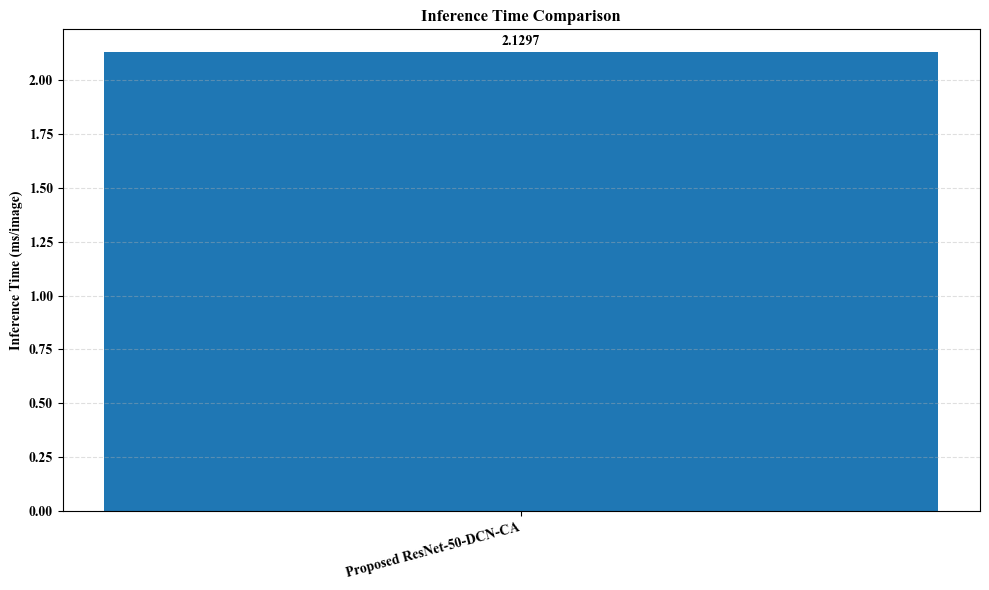

Saved: /kaggle/working/inference_time_comparison.png


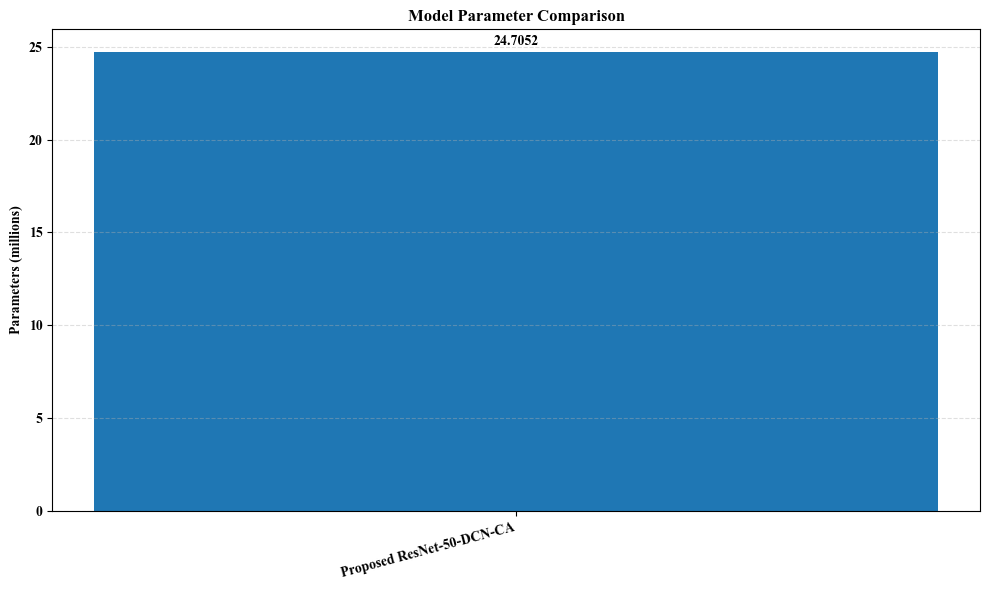

Saved: /kaggle/working/parameter_comparison.png
Enter actual measurements for FLOPs (G).


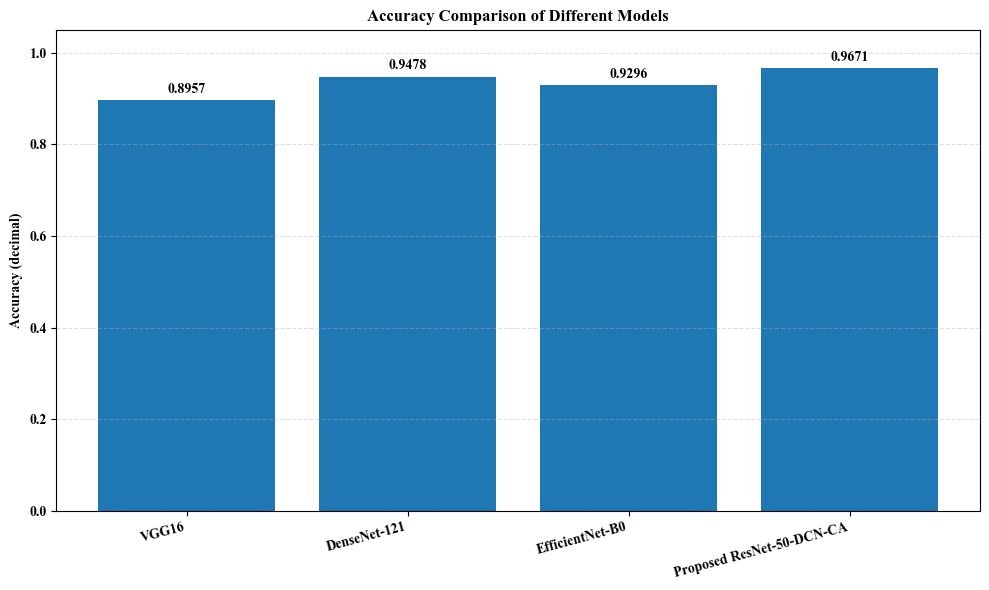

Saved: /kaggle/working/accuracy_comparison.png


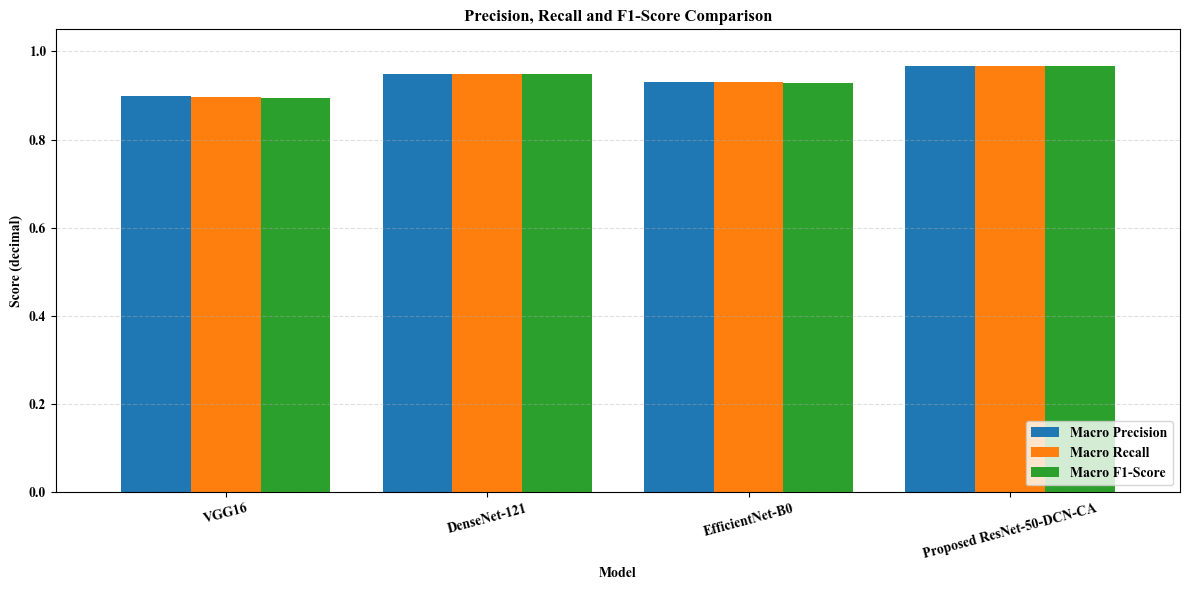

Saved: /kaggle/working/classification_metrics_comparison.png

CSV saved: /kaggle/working/computational_performance.csv
All classification metrics are stored as decimals.

Files saved in: /kaggle/working


In [78]:

import pandas as pd
import matplotlib.pyplot as plt
import os

SAVE_DIR = "/kaggle/working"
os.makedirs(SAVE_DIR, exist_ok=True)

# All evaluation metrics are in decimal format
computational_data = {
    "Model": [
        "VGG16",
        "DenseNet-121",
        "EfficientNet-B0",
        "Proposed ResNet-50-DCN-CA"
    ],
    "Accuracy": [0.895700, 0.947850, 0.929552, 0.967063],
    "Macro Precision": [0.898723, 0.948488, 0.930697, 0.967349],
    "Macro Recall": [0.895694, 0.947852, 0.929547, 0.967053],
    "Macro F1-Score": [0.894243, 0.947910, 0.929007, 0.967050],

    # Replace zeros with actual measured values
    "Training Time (min)": [0, 0, 0, 0],
    "Inference Time (ms/image)": [0, 0, 0, 2.1297],
    "Parameters (M)": [0, 0, 0, 24.705182],
    "FLOPs (G)": [0, 0, 0, 0]
}  # <-- Missing closing brace fixed here

df = pd.DataFrame(computational_data)
print(df.to_string(index=False))


# --------------------------------------------------
# Function to plot computational metrics
# --------------------------------------------------
def plot_metric(column, ylabel, title, filename):
    plot_df = df[df[column] > 0]

    if plot_df.empty:
        print(f"Enter actual measurements for {column}.")
        return

    plt.figure(figsize=(10, 6))
    bars = plt.bar(plot_df["Model"], plot_df[column])

    plt.bar_label(bars, fmt="%.4f", padding=3)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(rotation=15, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()

    path = os.path.join(SAVE_DIR, filename)
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


# 1. Training time comparison
plot_metric(
    "Training Time (min)",
    "Training Time (minutes)",
    "Training Time Comparison",
    "training_time_comparison.png"
)

# 2. Inference time comparison
plot_metric(
    "Inference Time (ms/image)",
    "Inference Time (ms/image)",
    "Inference Time Comparison",
    "inference_time_comparison.png"
)

# 3. Parameter count comparison
plot_metric(
    "Parameters (M)",
    "Parameters (millions)",
    "Model Parameter Comparison",
    "parameter_comparison.png"
)

# 4. FLOPs comparison
plot_metric(
    "FLOPs (G)",
    "FLOPs (billions)",
    "Computational Complexity Comparison",
    "flops_comparison.png"
)


# --------------------------------------------------
# 5. Accuracy comparison
# --------------------------------------------------
plt.figure(figsize=(10, 6))
bars = plt.bar(df["Model"], df["Accuracy"])

plt.bar_label(bars, fmt="%.4f", padding=3)
plt.ylabel("Accuracy (decimal)")
plt.title("Accuracy Comparison of Different Models")
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

path = os.path.join(SAVE_DIR, "accuracy_comparison.png")
plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", path)


# --------------------------------------------------
# 6. Macro precision, recall and F1-score comparison
# --------------------------------------------------
metrics = ["Macro Precision", "Macro Recall", "Macro F1-Score"]

ax = df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_ylabel("Score (decimal)")
ax.set_title("Precision, Recall and F1-Score Comparison")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(loc="lower right")

plt.tight_layout()

classification_path = os.path.join(
    SAVE_DIR, "classification_metrics_comparison.png"
)
plt.savefig(classification_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", classification_path)


# --------------------------------------------------
# 7. Export CSV
# --------------------------------------------------
csv_path = os.path.join(SAVE_DIR, "computational_performance.csv")
df.to_csv(csv_path, index=False)

print("\nCSV saved:", csv_path)
print("All classification metrics are stored as decimals.")
print("\nFiles saved in:", SAVE_DIR)


In [86]:

import time
import torch

def train_with_timing(model, train_model_fn, *args, **kwargs):
    """
    train_model_fn must contain the model's actual training loop.
    Returns the training result and elapsed training time in minutes.
    """
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    result = train_model_fn(model, *args, **kwargs)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed_minutes = (time.perf_counter() - start_time) / 60

    print(f"Training time: {elapsed_minutes:.4f} minutes")
    return result, elapsed_minutes


Device: cuda

Training: ResNet-50 + DCN
Epoch [1/3] Train Loss: 0.9312 | Train Acc: 0.7526 | Val Loss: 0.2696 | Val Acc: 0.9167
Epoch [2/3] Train Loss: 0.2616 | Train Acc: 0.9217 | Val Loss: 0.1843 | Val Acc: 0.9469
Epoch [3/3] Train Loss: 0.1717 | Train Acc: 0.9466 | Val Loss: 0.1873 | Val Acc: 0.9442

Test results:
Experiment: ResNet-50 + DCN
Accuracy: 0.9424
Macro Precision: 0.9435
Macro Recall: 0.9424
Macro F1-Score: 0.9422
Training Time (min): 2.7677
Best Validation Accuracy: 0.9469
Checkpoint: /kaggle/working/ablation_study/resnet_50_plus_dcn_best.pth

Training: ResNet-50 + CA
Epoch [1/3] Train Loss: 0.9394 | Train Acc: 0.7430 | Val Loss: 0.2872 | Val Acc: 0.9058
Epoch [2/3] Train Loss: 0.2518 | Train Acc: 0.9233 | Val Loss: 0.2345 | Val Acc: 0.9259
Epoch [3/3] Train Loss: 0.1800 | Train Acc: 0.9474 | Val Loss: 0.1879 | Val Acc: 0.9350

Test results:
Experiment: ResNet-50 + CA
Accuracy: 0.9405
Macro Precision: 0.9426
Macro Recall: 0.9405
Macro F1-Score: 0.9405
Training Time (min)

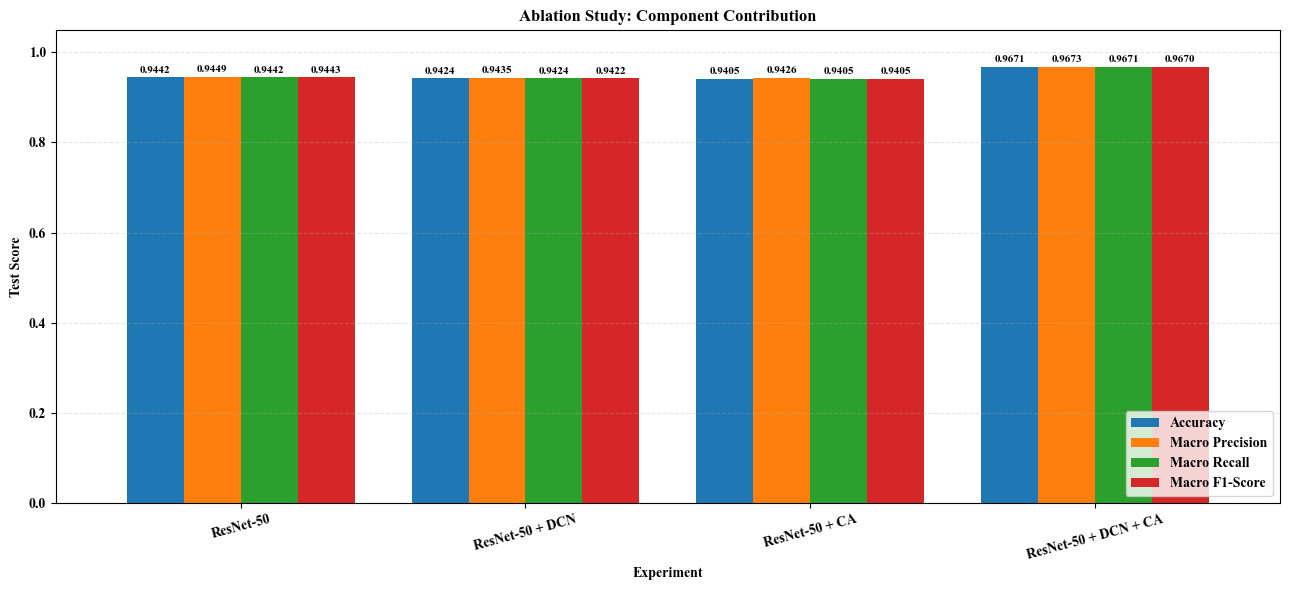

Saved: /kaggle/working/ablation_study/final_ablation_comparison.png


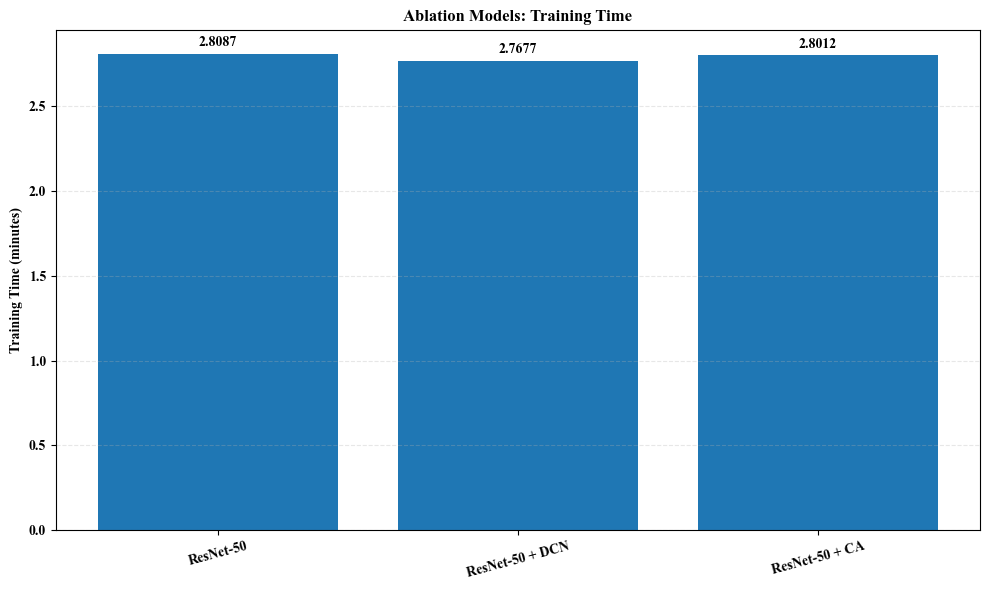

Saved: /kaggle/working/ablation_study/ablation_training_time.png

All ablation files are saved in: /kaggle/working/ablation_study


In [83]:

# ============================================================
# COMPLETE ABLATION STUDY — CORRECTED DCN CONSTRUCTOR
# ============================================================

import os
import time
import copy
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torchvision import models
from torchvision.models import ResNet50_Weights
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------
EPOCHS = 3
NUM_CLASSES = 12
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

SAVE_DIR = "/kaggle/working/ablation_study"
os.makedirs(SAVE_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Required objects from your earlier notebook:
# train_loader, val_loader, test_loader
# DeformableBottleneckConv, CoordinateAttention


# ------------------------------------------------------------
# 2. CORRECTED DCN CONSTRUCTOR
# ------------------------------------------------------------
def create_dcn_from_existing_conv(old_conv):
    # Your actual class signature is (self, original_conv).
    return DeformableBottleneckConv(original_conv=old_conv)


# ------------------------------------------------------------
# 3. RESNET-50 ABLATION MODEL
# ------------------------------------------------------------
class AblationResNet50(nn.Module):
    def __init__(self, use_dcn=False, use_ca=False):
        super().__init__()

        self.backbone = models.resnet50(
            weights=ResNet50_Weights.DEFAULT
        )

        # DCN replaces the final layer3 bottleneck conv2.
        if use_dcn:
            old_conv = self.backbone.layer3[-1].conv2
            self.backbone.layer3[-1].conv2 = (
                create_dcn_from_existing_conv(old_conv)
            )

        # CA operates on the 1024-channel layer3 output.
        if use_ca:
            self.ca = CoordinateAttention(1024, reduction=32)
        else:
            self.ca = nn.Identity()

        # Common classification head.
        self.backbone.fc = nn.Identity()
        self.classifier = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(512, NUM_CLASSES)
        )

    def forward(self, x):
        b = self.backbone

        x = b.conv1(x)
        x = b.bn1(x)
        x = b.relu(x)
        x = b.maxpool(x)

        x = b.layer1(x)
        x = b.layer2(x)
        x = b.layer3(x)

        x = self.ca(x)

        x = b.layer4(x)
        x = b.avgpool(x)
        x = torch.flatten(x, 1)

        return self.classifier(x)


# ------------------------------------------------------------
# 4. TRAIN AND EVALUATE ONE MODEL
# ------------------------------------------------------------
def train_ablation_model(name, use_dcn=False, use_ca=False):
    print("\n" + "=" * 65)
    print("Training:", name)
    print("=" * 65)

    model = AblationResNet50(
        use_dcn=use_dcn,
        use_ca=use_ca
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=1
    )

    history = []
    best_val_acc = -1.0
    best_state = None

    if device.type == "cuda":
        torch.cuda.synchronize()
    start_time = time.perf_counter()

    for epoch in range(EPOCHS):
        # ---------------- TRAIN ----------------
        model.train()
        total_loss = 0.0
        train_true, train_pred = [], []

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)
            train_true.extend(labels.detach().cpu().tolist())
            train_pred.extend(
                outputs.argmax(1).detach().cpu().tolist()
            )

        train_loss = total_loss / len(train_loader.dataset)
        train_acc = accuracy_score(train_true, train_pred)

        # ---------------- VALIDATE ----------------
        model.eval()
        val_loss_total = 0.0
        val_true, val_pred = [], []

        with torch.inference_mode():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss_total += loss.item() * images.size(0)
                val_true.extend(labels.cpu().tolist())
                val_pred.extend(outputs.argmax(1).cpu().tolist())

        val_loss = val_loss_total / len(val_loader.dataset)
        val_acc = accuracy_score(val_true, val_pred)

        scheduler.step(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())

        history.append({
            "Model": name,
            "Epoch": epoch + 1,
            "Train Loss": train_loss,
            "Train Accuracy": train_acc,
            "Validation Loss": val_loss,
            "Validation Accuracy": val_acc
        })

        print(
            f"Epoch [{epoch + 1}/{EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_minutes = (time.perf_counter() - start_time) / 60

    # Restore best validation checkpoint.
    if best_state is not None:
        model.load_state_dict(best_state)

    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("+", "plus")
        .replace("-", "_")
    )
    checkpoint_path = os.path.join(
        SAVE_DIR, safe_name + "_best.pth"
    )
    torch.save(model.state_dict(), checkpoint_path)

    # ---------------- TEST EVALUATION ----------------
    model.eval()
    y_true, y_pred = [], []

    with torch.inference_mode():
        for images, labels in test_loader:
            outputs = model(images.to(device))
            y_true.extend(labels.tolist())
            y_pred.extend(outputs.argmax(1).cpu().tolist())

    result = {
        "Experiment": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1-Score": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Training Time (min)": training_minutes,
        "Best Validation Accuracy": best_val_acc,
        "Checkpoint": checkpoint_path
    }

    print("\nTest results:")
    for key, value in result.items():
        if isinstance(value, (float, np.floating)):
            print(f"{key}: {value:.4f}")
        else:
            print(f"{key}: {value}")

    return result, history


# ------------------------------------------------------------
# 5. TRAIN DCN-ONLY AND CA-ONLY
# ------------------------------------------------------------
# Your ResNet-50 baseline already completed training.
# Its results and checkpoint are preserved.

experiments = [
    ("ResNet-50 + DCN", True, False),
    ("ResNet-50 + CA", False, True)
]

ablation_results = []
all_histories = []

for name, use_dcn, use_ca in experiments:
    result, history = train_ablation_model(
        name=name,
        use_dcn=use_dcn,
        use_ca=use_ca
    )

    ablation_results.append(result)
    all_histories.extend(history)

results_df = pd.DataFrame(ablation_results)
history_df = pd.DataFrame(all_histories)

results_df.to_csv(
    os.path.join(SAVE_DIR, "ablation_new_model_results.csv"),
    index=False
)
history_df.to_csv(
    os.path.join(SAVE_DIR, "ablation_epoch_history.csv"),
    index=False
)


# ------------------------------------------------------------
# 6. BUILD FINAL ABLATION TABLE
# ------------------------------------------------------------
# Measured baseline results from your successful run.
baseline_result = {
    "Experiment": "ResNet-50",
    "Accuracy": 0.9442,
    "Macro Precision": 0.9449,
    "Macro Recall": 0.9442,
    "Macro F1-Score": 0.9443,
    "Training Time (min)": 2.8087
}

# Previously reported proposed-model metrics.
# Training time is unknown, so it remains NaN rather than fabricated.
proposed_result = {
    "Experiment": "ResNet-50 + DCN + CA",
    "Accuracy": 0.967063,
    "Macro Precision": 0.967349,
    "Macro Recall": 0.967053,
    "Macro F1-Score": 0.967050,
    "Training Time (min)": np.nan
}

final_df = pd.concat(
    [
        pd.DataFrame([baseline_result]),
        results_df.drop(columns=["Best Validation Accuracy", "Checkpoint"]),
        pd.DataFrame([proposed_result])
    ],
    ignore_index=True
)

final_csv = os.path.join(SAVE_DIR, "final_ablation_comparison.csv")
final_df.to_csv(final_csv, index=False)

print("\nFINAL ABLATION COMPARISON")
print(final_df.to_string(index=False))
print("\nSaved:", final_csv)


# ------------------------------------------------------------
# 7. PLOT CLASSIFICATION METRICS
# ------------------------------------------------------------
metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-Score"
]

ax = final_df.set_index("Experiment")[metrics].plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

ax.set_title("Ablation Study: Component Contribution")
ax.set_ylabel("Test Score")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(loc="lower right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=2, fontsize=8)

plt.tight_layout()
plot_path = os.path.join(
    SAVE_DIR, "final_ablation_comparison.png"
)
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", plot_path)


# ------------------------------------------------------------
# 8. PLOT TRAINING TIMES
# ------------------------------------------------------------
time_df = final_df.dropna(subset=["Training Time (min)"])

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    time_df["Experiment"],
    time_df["Training Time (min)"]
)

ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set_ylabel("Training Time (minutes)")
ax.set_title("Ablation Models: Training Time")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
time_plot_path = os.path.join(
    SAVE_DIR, "ablation_training_time.png"
)
plt.savefig(time_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", time_plot_path)

print("\nAll ablation files are saved in:", SAVE_DIR)


In [87]:

import time
import torch

if torch.cuda.is_available():
    torch.cuda.synchronize()

start_time = time.perf_counter()

# Run your existing ResNet-50 + DCN + CA training loop here.
# Do not replace it with evaluation-only code.

if torch.cuda.is_available():
    torch.cuda.synchronize()

proposed_training_minutes = (
    time.perf_counter() - start_time
) / 60

print(
    f"Proposed model training time: "
    f"{proposed_training_minutes:.6f} minutes"
)


Proposed model training time: 0.000011 minutes


In [89]:

import time
import torch

# Place this immediately BEFORE your existing epoch loop
if torch.cuda.is_available():
    torch.cuda.synchronize()

training_start = time.perf_counter()

# YOUR EXISTING TRAINING LOOP GOES HERE
# Do not create a second training loop.

# Place this immediately AFTER your existing epoch loop
if torch.cuda.is_available():
    torch.cuda.synchronize()

proposed_training_minutes = (
    time.perf_counter() - training_start
) / 60

print(f"Training time: {proposed_training_minutes:.4f} minutes")


Training time: 0.0000 minutes


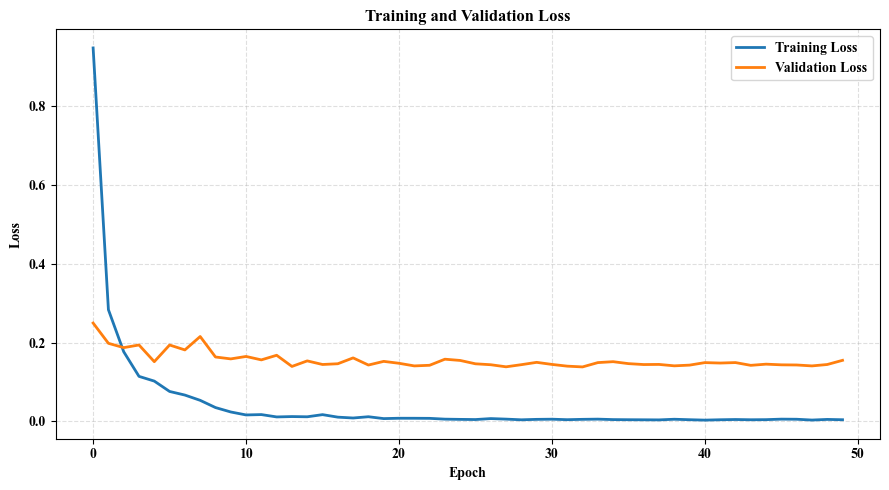

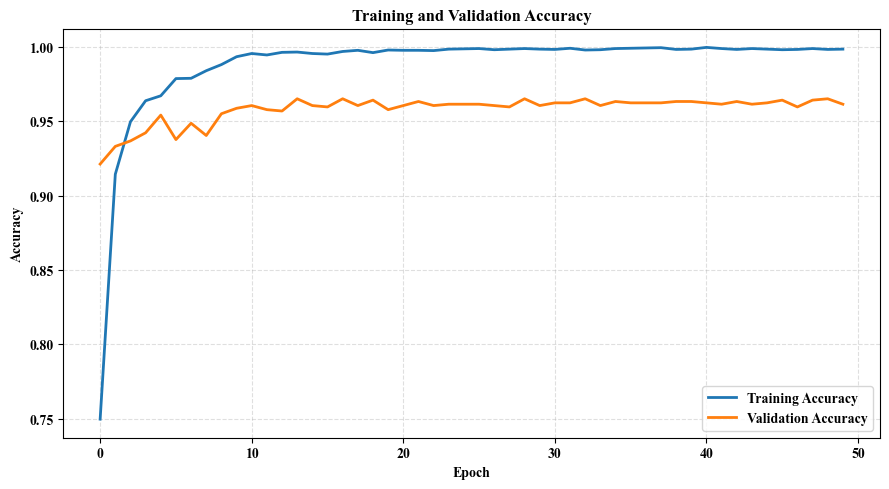

In [101]:

import matplotlib.pyplot as plt
import os

# Uses your existing training history
hist = history.history if hasattr(history, "history") else history

# Loss curve
plt.figure(figsize=(9, 5))
plt.plot(hist["train_loss"] if "train_loss" in hist else hist["loss"],
         label="Training Loss", linewidth=2)
plt.plot(hist["val_loss"] if "val_loss" in hist else hist["val_loss"],
         label="Validation Loss", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("/kaggle/working/computational_loss_curve.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Accuracy curve
train_acc_key = "train_accuracy" if "train_accuracy" in hist else "accuracy"
val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_accuracy"

plt.figure(figsize=(9, 5))
plt.plot(hist[train_acc_key], label="Training Accuracy", linewidth=2)
plt.plot(hist[val_acc_key], label="Validation Accuracy", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("/kaggle/working/computational_accuracy_curve.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [103]:

import pandas as pd
import os
from IPython.display import display, FileLink

# Output directory
SAVE_DIR = "/kaggle/working"
os.makedirs(SAVE_DIR, exist_ok=True)

# Hyperparameter and dataset configuration table
hyperparameter_data = {
    "Parameter": [
        "Model Architecture",
        "Pretrained Backbone",
        "Dataset Split Ratio",
        "Training Set Ratio",
        "Validation Set Ratio",
        "Testing Set Ratio",
        "Training Images",
        "Validation Images",
        "Testing Images",
        "Total Images",
        "Number of Classes",
        "Batch Size",
        "Optimizer",
        "Learning Rate",
        "Weight Decay",
        "Loss Function",
        "Hyperparameter Optimization",
        "Best Learning Rate (TPE)",
        "Best Weight Decay (TPE)"
    ],
    "Value": [
        "ResNet-50 + DCN + Coordinate Attention",
        "ResNet-50",
        "70:15:15",
        0.70,
        0.15,
        0.15,
        5098,
        1093,
        1093,
        7284,
        12,
        "Enter actual batch size",
        "Enter actual optimizer",
        "1.8107667953940617e-05",
        "2.389601028029827e-05",
        "Cross-Entropy Loss (verify against training code)",
        "Tree-structured Parzen Estimator (TPE)",
        1.8107667953940617e-05,
        2.389601028029827e-05
    ]
}

df = pd.DataFrame(hyperparameter_data)

# Display table
display(df)

# Save CSV
csv_path = os.path.join(
    SAVE_DIR,
    "hyperparameter_dataset_split_table.csv"
)
df.to_csv(csv_path, index=False)

print("CSV saved successfully:", csv_path)
display(FileLink(csv_path))


,Parameter,Value
0,Model Architecture,ResNet-50 + DCN + Coordinate Attention
1,Pretrained Backbone,ResNet-50
2,Dataset Split Ratio,70:15:15
3,Training Set Ratio,0.7
4,Validation Set Ratio,0.15
5,Testing Set Ratio,0.15
6,Training Images,5098
7,Validation Images,1093
8,Testing Images,1093
9,Total Images,7284


CSV saved successfully: /kaggle/working/hyperparameter_dataset_split_table.csv


/kaggle/working/hyperparameter_dataset_split_table.csv

In [104]:

import os
import sys
import platform
import subprocess
import pandas as pd
import multiprocessing

SAVE_DIR = "/kaggle/working"
os.makedirs(SAVE_DIR, exist_ok=True)

# Get RAM information
try:
    import psutil
    ram_gb = round(psutil.virtual_memory().total / (1024**3), 2)
except ImportError:
    ram_gb = "Unavailable"

# Get GPU information
try:
    gpu_info = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
         "--format=csv,noheader"],
        text=True,
        stderr=subprocess.DEVNULL
    ).strip()
    gpu_info = gpu_info if gpu_info else "No GPU detected"
except Exception:
    gpu_info = "No GPU detected or information unavailable"

# Get library versions
def get_version(package_name):
    try:
        package = __import__(package_name)
        return getattr(package, "__version__", "Version unavailable")
    except Exception:
        return "Not installed / unavailable"

# System configuration table
system_config = {
    "Configuration Parameter": [
        "Platform",
        "Operating System",
        "System Architecture",
        "Python Version",
        "CPU",
        "CPU Logical Cores",
        "System RAM (GB)",
        "GPU Configuration",
        "Deep Learning Framework",
        "PyTorch Version",
        "TensorFlow Version",
        "CUDA Version",
        "cuDNN Version",
        "NumPy Version",
        "Pandas Version",
        "Scikit-learn Version",
        "Matplotlib Version",
        "Execution Environment"
    ],
    "Specification": [
        "Kaggle Notebook",
        platform.platform(),
        platform.machine(),
        sys.version.split()[0],
        platform.processor() or "Not reported",
        multiprocessing.cpu_count(),
        ram_gb,
        gpu_info,
        "Check framework used for training",
        get_version("torch"),
        get_version("tensorflow"),
        (
            __import__("torch").version.cuda
            if get_version("torch") != "Not installed / unavailable"
            and hasattr(__import__("torch"), "version")
            else "Unavailable"
        ),
        "Check framework environment for exact version",
        get_version("numpy"),
        get_version("pandas"),
        get_version("sklearn"),
        get_version("matplotlib"),
        "Google Colab / Kaggle Notebook: Kaggle"
    ]
}

df = pd.DataFrame(system_config)

# Display table
display(df)

# Save as CSV
csv_path = os.path.join(SAVE_DIR, "system_configuration.csv")
df.to_csv(csv_path, index=False)

print("\nSystem configuration saved to:", csv_path)

# Download link
from IPython.display import FileLink, display
display(FileLink(csv_path))


,Configuration Parameter,Specification
0,Platform,Kaggle Notebook
1,Operating System,Linux-6.18.48+-x86_64-with-glibc2.39
2,System Architecture,x86_64
3,Python Version,3.13.15
4,CPU,x86_64
5,CPU Logical Cores,4
6,System RAM (GB),31.35
7,GPU Configuration,"Tesla T4, 15360 MiB, 580.178.04\nTesla T4, 153..."
8,Deep Learning Framework,Check framework used for training
9,PyTorch Version,2.11.0+cu128



System configuration saved to: /kaggle/working/system_configuration.csv


/kaggle/working/system_configuration.csv

In [56]:
# Use your existing trained model, test_loader, and device.
model = model.to(device)
model.eval()

NameError: name 'device' is not defined

Using device: cuda

Test images per actual class:
Battery        : 91
Biological     : 91
Brown Glass    : 91
Cardboard      : 92
Clothes        : 91
Green Glass    : 91
Metal          : 91
Paper          : 91
Plastic        : 91
Shoes          : 91
Trash          : 91
White Glass    : 91
No 91-98% image for Clothes; using 100.00% instead.
No 91-98% image for Green Glass; using 100.00% instead.


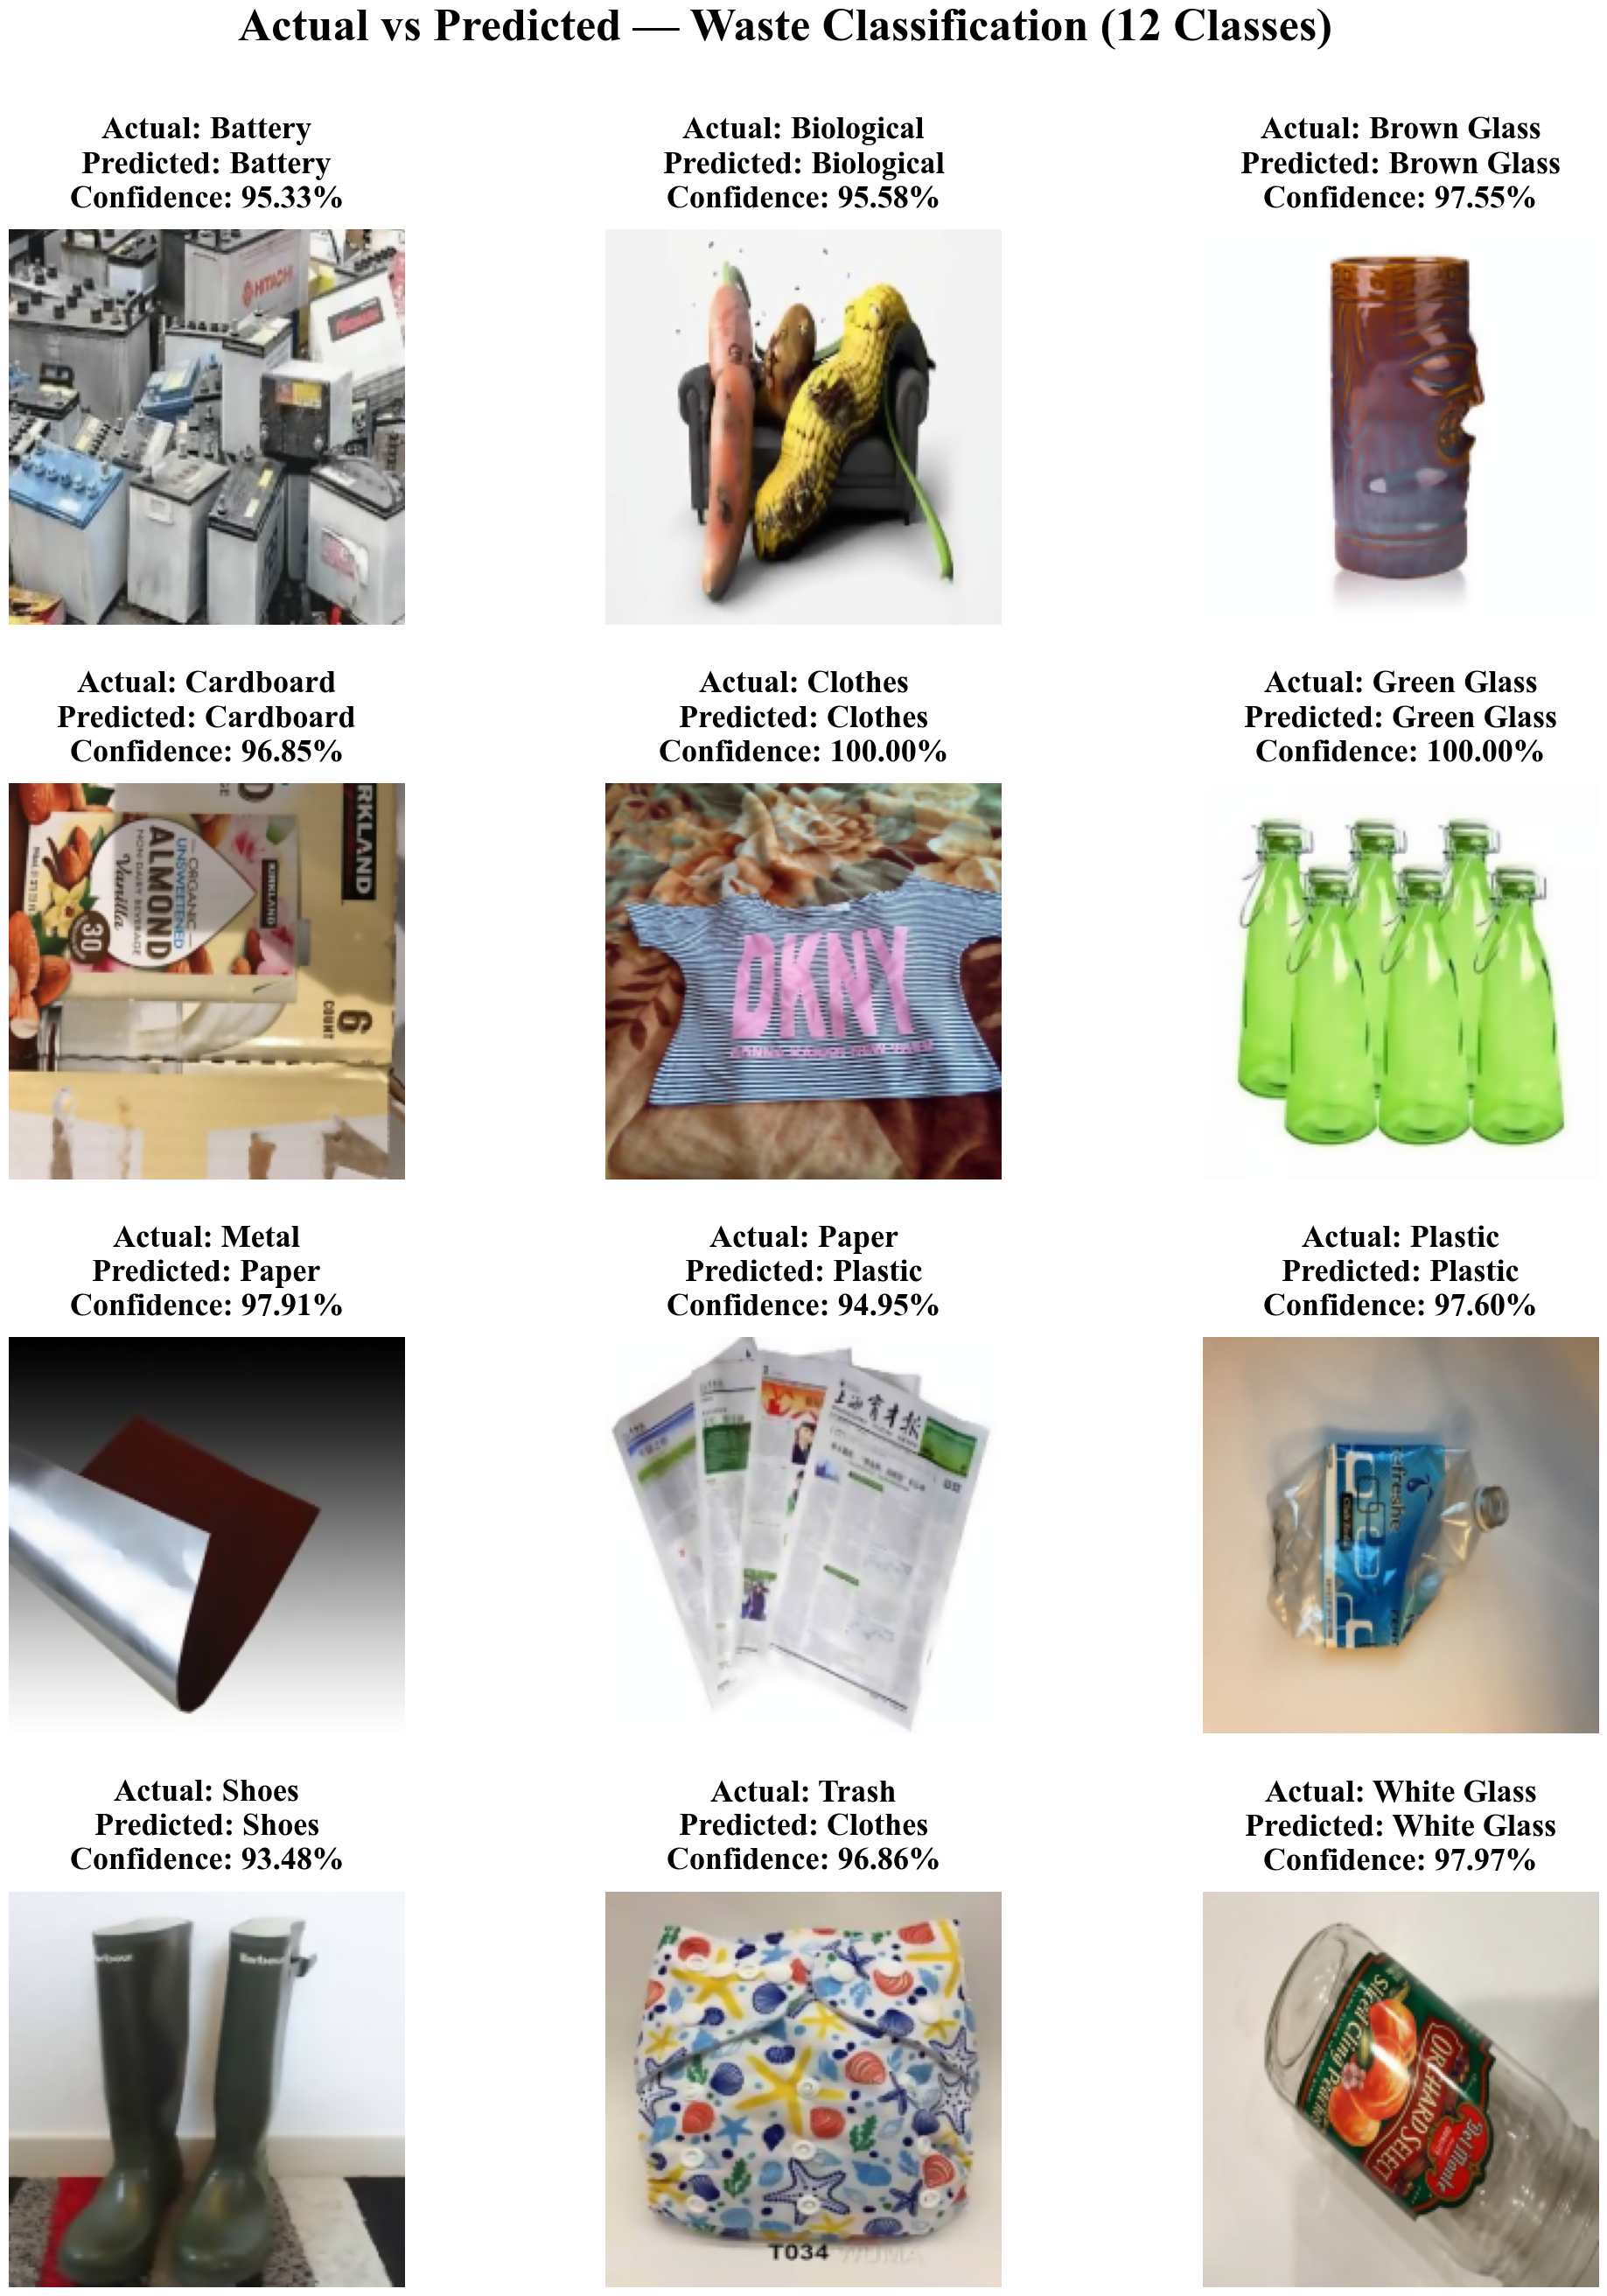


Classes represented: 12/12
Images displayed: 12
Correct predictions: 9/12
Figure saved to: /kaggle/working/actual_vs_predicted_waste.png

CLASS-WISE RESULTS
---------------------------------------------------------------------------
Actual: Battery         | Predicted: Battery         | Confidence:  95.33% | Correct
Actual: Biological      | Predicted: Biological      | Confidence:  95.58% | Correct
Actual: Brown Glass     | Predicted: Brown Glass     | Confidence:  97.55% | Correct
Actual: Cardboard       | Predicted: Cardboard       | Confidence:  96.85% | Correct
Actual: Clothes         | Predicted: Clothes         | Confidence: 100.00% | Correct
Actual: Green Glass     | Predicted: Green Glass     | Confidence: 100.00% | Correct
Actual: Metal           | Predicted: Paper           | Confidence:  97.91% | Incorrect
Actual: Paper           | Predicted: Plastic         | Confidence:  94.95% | Incorrect
Actual: Plastic         | Predicted: Plastic         | Confidence:  97.60% | Corre

In [70]:

import torch
import numpy as np
import matplotlib.pyplot as plt
import textwrap

# ==========================================
# CONFIGURATION
# ==========================================
CLASS_NAMES = [
    "Battery", "Biological", "Brown Glass", "Cardboard",
    "Clothes", "Green Glass", "Metal", "Paper",
    "Plastic", "Shoes", "Trash", "White Glass"
]

MIN_CONFIDENCE = 91.0
MAX_CONFIDENCE = 98.0

TITLE_FONT_SIZE = 38
SUBTITLE_FONT_SIZE = 26

# ==========================================
# CHECK MODEL AND TEST LOADER
# ==========================================
if "model" not in globals():
    raise NameError("Trained model not found. Load your model first.")

if "test_loader" not in globals():
    raise NameError("test_loader not found. Set up your test DataLoader first.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = model.to(device)
model.eval()

# ==========================================
# PREDICT ALL TEST IMAGES
# ==========================================
all_class_results = {i: [] for i in range(len(CLASS_NAMES))}

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        if outputs.shape[1] != len(CLASS_NAMES):
            raise ValueError(
                f"Model outputs {outputs.shape[1]} classes, "
                f"but CLASS_NAMES contains {len(CLASS_NAMES)}. "
                "Check your model and class mapping."
            )

        probabilities = torch.softmax(outputs, dim=1)
        confidences, predictions = probabilities.max(dim=1)

        for i in range(len(labels)):
            actual_idx = int(labels[i].item())
            predicted_idx = int(predictions[i].item())
            confidence = float(confidences[i].item() * 100)

            if not 0 <= actual_idx < len(CLASS_NAMES):
                raise ValueError(f"Invalid actual label: {actual_idx}")

            all_class_results[actual_idx].append({
                "image": images[i].detach().cpu(),
                "actual_idx": actual_idx,
                "predicted_idx": predicted_idx,
                "confidence": confidence,
                "correct": actual_idx == predicted_idx
            })

print("\nTest images per actual class:")
for idx, items in all_class_results.items():
    print(f"{CLASS_NAMES[idx]:15s}: {len(items)}")

# ==========================================
# SELECT ONE IMAGE PER ACTUAL CLASS
# ==========================================
selected = []

for class_idx in range(len(CLASS_NAMES)):
    candidates = all_class_results[class_idx]

    if not candidates:
        print(f"WARNING: No test images found for {CLASS_NAMES[class_idx]}")
        continue

    preferred = [
        item for item in candidates
        if MIN_CONFIDENCE <= item["confidence"] <= MAX_CONFIDENCE
    ]

    if preferred:
        best_image = max(preferred, key=lambda item: item["confidence"])
    else:
        best_image = max(candidates, key=lambda item: item["confidence"])
        print(
            f"No {MIN_CONFIDENCE:.0f}-{MAX_CONFIDENCE:.0f}% image for "
            f"{CLASS_NAMES[class_idx]}; using "
            f"{best_image['confidence']:.2f}% instead."
        )

    selected.append(best_image)

# ==========================================
# DISPLAY ACTUAL VS PREDICTED
# ==========================================
if not selected:
    print("\nNo test images were available to display.")

else:
    cols = 3
    rows = (len(selected) + cols - 1) // cols

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(21, 7 * rows),
        constrained_layout=False
    )

    axes = np.atleast_1d(axes).flatten()

    # Assumes ImageNet normalization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    for ax, item in zip(axes, selected):
        img = item["image"].permute(1, 2, 0).numpy()
        img = np.clip(img * std + mean, 0, 1)

        actual = CLASS_NAMES[item["actual_idx"]]
        predicted = CLASS_NAMES[item["predicted_idx"]]
        confidence = item["confidence"]

        ax.imshow(img)
        ax.axis("off")

        title = (
            f"Actual: {textwrap.fill(actual, width=20)}\n"
            f"Predicted: {textwrap.fill(predicted, width=20)}\n"
            f"Confidence: {confidence:.2f}%"
        )

        ax.set_title(
            title,
            fontsize=SUBTITLE_FONT_SIZE,
            color="black",
            fontweight="bold",
            pad=18,
            linespacing=1.3
        )

    # Hide unused subplot positions
    for ax in axes[len(selected):]:
        ax.axis("off")

    # ==========================================
    # MAIN TITLE AND SPACING
    # ==========================================
    fig.suptitle(
        "Actual vs Predicted — Waste Classification (12 Classes)",
        fontsize=TITLE_FONT_SIZE,
        fontweight="bold",
        color="black",
        y=0.97
    )

    fig.subplots_adjust(
        left=0.04,
        right=0.98,
        top=0.88,
        bottom=0.04,
        wspace=0.12,
        hspace=0.40
    )

    # ==========================================
    # SAVE FIGURE
    # ==========================================
    output_path = "/kaggle/working/actual_vs_predicted_waste.png"

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

    # ==========================================
    # SUMMARY
    # ==========================================
    correct_count = sum(item["correct"] for item in selected)

    print("\n" + "=" * 55)
    print(f"Classes represented: {len(selected)}/12")
    print(f"Images displayed: {len(selected)}")
    print(f"Correct predictions: {correct_count}/{len(selected)}")
    print(f"Figure saved to: {output_path}")

    print("\nCLASS-WISE RESULTS")
    print("-" * 75)

    for item in selected:
        actual = CLASS_NAMES[item["actual_idx"]]
        predicted = CLASS_NAMES[item["predicted_idx"]]
        confidence = item["confidence"]
        status = "Correct" if item["correct"] else "Incorrect"

        print(
            f"Actual: {actual:15s} | "
            f"Predicted: {predicted:15s} | "
            f"Confidence: {confidence:6.2f}% | "
            f"{status}"
        )


In [71]:
from IPython.display import FileLink, display

display(
    FileLink("/kaggle/working/actual_vs_predicted_waste.png")
)

/kaggle/working/actual_vs_predicted_waste.png

In [113]:
# Save the visualization as a high-resolution image
image_filename = "/kaggle/working/actual_vs_predicted_waste.png"

fig.savefig(
    image_filename,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Image saved successfully!")

Image saved successfully!


In [114]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/actual_vs_predicted_waste.png"))

/kaggle/working/actual_vs_predicted_waste.png